# Fair test of Gemma's BFS steering dial: a demo of `method.py`

**Artifact** `art_FJMIE9T9_PMv` (iteration 8, claim G) · model `google/gemma-3-4b-it` (bf16) · task **T1** (write
`solve(grid, start, goal)`, a grid path finder) · one fork.

Under a neutral *twin* prompt ("Do not use house for this task.") Gemma's program forks right after a fixed
32-token opening **c\*** (`def solve(grid, start, goal):` … `cols = len(grid[0])`): the next token is either a
BFS-type token (`'\n'`, `if`, ` queue`, `q`, class **B**) or ` visited` (class **D**, a DFS program). Iteration 7
found a rank-4 **DAS** subspace at decoder block 17 that works as a *dial*. The edit
$f(h) = h + \lambda R_k (c_Y - R_k^\top h)$ moves the block-17 state's $k$ subspace coordinates to the BFS (or DFS)
class mean $c_Y$. This artifact is the **fair test** of that dial: the missing cells of a 2×2 design on the
**same 50 common-random-number (CRN) slots**:

| | **c\* prefilled** (teacher-forced opening) | **free generation** |
|---|---|---|
| **prompt**: "Write a correct solution that uses breadth-first search (BFS)." | `G1a` | `G1c` (+ 7 more wordings, `G1e`) |
| **dial**: DAS rank 4, λ = 1, block 17 | `P-DAS-bfs` | `F-DAS-r4-bfs-1.0` (edit at a committed decision position) |
| twin baseline (no edit) | `P-twin` | `F-twin` |

It also runs dormancy checks of the subspace at ranks 1, 2, 4, 8, a layer sweep, and hash-chained commitments
written before every batch of samples.

**Recorded results (1,320 programs, RTX 4090):**
1. *Prefill-matched prompting collapses.* `G1a` writes BFS in 50/50 programs but **0/50 are correct**. Under the
   forced-BFS prompt the c\* prefill is off-policy (log P(c\*) ≈ −13 nats vs −0.1 under the twin), so the fork token
   becomes ` queue` (p ≈ 0.97). That list-based BFS lacks the start/goal wall check and fails the hidden wall case.
   The prefilled dial gets **39/50** (39/0 discordant slots, exact McNemar p = 3.6e-12).
2. *The free-generation dial works.* Correct BFS goes from **13/50** (free twin) to **38/50** with the dial (p = 2.1e-7).
3. *In free generation the dial does not beat prompting.* The committed prompt `G1c` gets 32/50 (p = 0.21), and the
   best of 8 wordings gets 49/50.
4. *Dormancy.* The subspace carries almost none of the twins' natural variance. The verdict at every k is
   DORMANT/OFF-MANIFOLD HANDLE.

### What runs here
`method.py` is a stage dispatcher (`python method.py --stage s0 | gpu1 | commit2 | fcells | gpu_extra | tf_extra |
label | analysis | …`). Its GPU stages sample Gemma-3-4B on a 24 GB GPU. They do not fit a CPU notebook in 10
minutes, and the model is gated. So the notebook keeps **every stage function of `method.py` verbatim** (defined, not
called) and runs on CPU, on the real recorded data in `mini_demo_data.json`, every part of the method that does not
need a forward pass of the model:

| step | runs here (CPU) | original stage |
|---|---|---|
| checker gate | the frozen T1 hidden tests reject the 5 hand-made mutants of the BFS reference | `s0` |
| commitments | write-once, hash-chained commitments, then the audit's chain check | `s0` (COMMIT #0) |
| edits | `_edits_ctx` builds the DAS / DiM / RAND edits of every free cell; applied to real block-17 states | `gpu1`, `fcells` |
| dormancy (iii) | natural variance of $R_k$ vs 1,000 Haar subspaces on iteration 7's 120 twin-variant states | `gpu1` (S3) |
| decision rule | the committed R1 / R2 / NOT_REACHED rule on the free twin's recorded trajectories | `commit2` |
| re-scoring | the hidden tests re-run on the recorded programs of the headline cells | `label` |
| statistics | `analysis8.analyze` verbatim: per-cell counts, exact McNemar, Holm, Newcombe, slot bootstrap, P1–P7 | `analysis` |

Everything that needs the model (sampling, teacher-forced fork distributions, recovery ratios, the layer sweep) is
**replayed** from the recorded outputs stored in `mini_demo_data.json`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py and the frozen T1 harness log with it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib, torch — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--index-url', 'https://download.pytorch.org/whl/cpu',
         '--extra-index-url', 'https://pypi.org/simple')

In [2]:
from __future__ import annotations

import argparse
import json
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- additional imports used by the vendored helpers (src/cfg.py, cfg8.py, tf8.py, gen8.py, analysis8.py,
#      commit.py, the T1 harness) and by the notebook's own cells
import base64
import hashlib
import math
import os
import shutil
import subprocess
import types
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone
from typing import Callable, Iterable

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

_T_START = time.time()
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss} | {level: <7} | {message}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("torch", torch.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])

torch 2.9.0+cpu | numpy 2.0.2 | python 3.12.14


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-42/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# The URL serves the last published copy; if that copy has another format than this notebook's, use the local file.
if data.get("about", {}).get("format_version") != 2:
    print("the downloaded copy has a different format; loading the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["about"]["artifact"])
print(data["about"]["unit"])
print(f'{len(data["examples"])} CRN slots; cells: {", ".join(data["about"]["cells"])}')

the downloaded copy has a different format; loading the local mini_demo_data.json
art_FJMIE9T9_PMv (Fair test of Gemma's BFS steering dial, iteration 8, claim G)
one example = one CRN slot (template w, slot k) of the free-generation design: S50 (50 slots, every cell) + HT30 (30 held-out W4/W5 slots, F-twin and F-DAS-r4-bfs-1.0 only)
80 CRN slots; cells: F-DAS-r1-bfs-0.5, F-DAS-r1-bfs-1.0, F-DAS-r4-bfs-0.5, F-DAS-r4-bfs-1.0, F-DAS-r4-dfs-1.0, F-DAS-s2-r4-bfs-1.0, F-DiM-bfs, F-DiM-dfs, F-RAND-r4-1.0, F-twin, G1a, G1b, G1c, G1d, G1e|F1|3, G1e|F2|3, G1e|F3|3, G1e|F4|3, G1e|F5|0, G1e|F5|1, G1e|F5|2, P-DAS-bfs, P-DAS-dfs, P-twin, REV-DAS, REV-FULL


## Configuration

The demo runs every CPU-side computation of the method. Its cost comes from the number of CRN slots analysed, the
number of programs re-run on the hidden tests (one sandboxed subprocess each), and the size of the Haar null. The
comment on each knob gives the original run's value. The defaults below are the scale that ran in this notebook
(see the timing note in the last cell). `RUN_GPU_STAGES` would run the original stages instead (it needs a 24 GB
GPU and a checkout of the artifact).

In [5]:
# ---------------- demo scale (original values in the comments)
SLOTS_PER_TEMPLATE = 10      # S50 slots per twin template W1..W5 (original: 10 -> all 50 CRN slots)
HT30_PER_TEMPLATE = 15       # held-out HT30 slots per template W4, W5 (original: 15 -> all 30)
RESCORE_CELLS = ['P-twin', 'G1a', 'P-DAS-bfs', 'F-twin', 'G1c', 'F-DAS-r4-bfs-1.0', 'F-DiM-bfs', 'G1e|F3|3']
                            # cells whose programs are re-run on the hidden tests (original audit, rederive_raw.py:
                            # P-twin, G1a, P-DAS-bfs, F-twin, G1c, F-DAS-r4-bfs-1.0, F-DiM-bfs, G1e|F3|3)
RESCORE_WORKERS = 2         # parallel sandbox processes (the label worker used 10)
N_HAAR_VAR_DEMO = 1000       # Haar subspaces in the natural-variance null (original: cfg8.N_HAAR_VAR = 1000)

# ---------------- the original pipeline (off: needs CUDA, gemma-3-4b-it and a checkout of the artifact)
RUN_GPU_STAGES = False      # True: run `method.py --stage ...` of the checkout below, in the original order
ARTIFACT_CHECKOUT = None    # path to the artifact folder (method.py, src/, inputs/, cache/), e.g. "/content/experiment-42"
DEV = "cuda" if torch.cuda.is_available() else "cpu"   # method.py puts every tensor on "cuda"
print("device:", DEV)

device: cpu


## 1. `method.py`: module header and input provenance

The module docstring lists the stages. The constants below tell the stages which inputs they read. Iteration 7's
artifacts (`art_HY7uYZz-OjRW`: the DAS maps and cached states, `art_veI9l_Rb9wDY`: the dormancy rule) and the
dataset dependency (`art_j3Rm_lr2nzR6`) are copied read-only into the workspace, and stage `s0` checks every copy
by sha256 (`COPIES`). In the notebook, a fresh scratch folder `artifact_root/` plays the artifact folder.

In [6]:
"""Iteration 8, claim G: a fair test of Gemma's BFS dial (google/gemma-3-4b-it, bf16, one RTX-class GPU).

Iteration 7 (art_HY7uYZz-OjRW) raised correct BFS programs from 11/50 (twin) to 42/50 with a rank-4 DAS edit at
block 17 after the c* prefill, and compared it with a forced-BFS prompt sampled WITHOUT the prefill (35/50). This
artifact runs the missing cells of the 2x2 {prompt, dial} x {c* prefilled, free generation} on the SAME 50 CRN slots,
plus dormancy checks of the subspace at ranks 1, 2, 4, 8.

Stages (`.venv/bin/python method.py --stage <name>`):
  s0       CPU: input hashes, labeller re-check, prompts, slot keys, decision-rule unit tests (U5), analysis8 on
           iteration 7's rows, dependency corpus -> known-solution pool, COMMIT #0
  gpu1     GPU: unit tests U1, U2, U3', U4'; engine check (P-twin, P-DAS-bfs); teacher-forced stage S3 (3a-3d) and
           COMMIT #1; G1 cells (G1a, G1b, G1c, P-DAS-dfs, G1d); free twin F-twin (S50 + HT30); reverse generation
  commit2  GPU: waits for the labels it needs, fixes the decision position per slot from F-twin, TF predictions at
           R2 positions, COMMIT #2
  fcells   GPU: edited free-generation cells (decode-time edit at i_d - 1), prefix check
  label    CPU label worker (frozen exp8 T1 labeller), follows data/raw_*.jsonl
  novelty / positioning / analysis / figures / outputs
"""

# method.py: ROOT = Path(__file__).resolve().parent. A notebook has no __file__: a fresh scratch folder plays the
# artifact folder (the vendored T1 suite, the recorded inputs, predictions/ and commitments.log are written there).
ROOT = Path.cwd() / "artifact_root"
shutil.rmtree(ROOT, ignore_errors=True)
ROOT.mkdir(parents=True)
sys.path.insert(0, str(ROOT / "src"))

GPU_STAGES = ("gpu1", "commit2", "fcells", "gputests", "gpu_extra", "tf_extra")
E38_REL = "ITER7/gen_art_experiment_38"
E33_REL = "ITER7/gen_art_experiment_33"


def artifact_dir(art_id: str, env: str, volume_rel: str) -> Path:
    """ONE location per input artifact, named by its id: the environment variable `env` if set; else the sibling
    folder named by the artifact id (the published repository's layout); else the run-volume layout, relative to this
    file's folder. Inputs are only ever READ there (copied into this workspace by hand, verified by stage s0)."""
    import os

    if os.environ.get(env):
        return Path(os.environ[env])
    sib = ROOT.parent / art_id
    return sib if sib.exists() else ROOT / volume_rel


ART_E38 = artifact_dir("art_HY7uYZz-OjRW", "AII_ART_HY7UYZZ_OJRW", "../../../iter_7/gen_art/gen_art_experiment_38")
ART_E33 = artifact_dir("art_veI9l_Rb9wDY", "AII_ART_VEI9L_RB9WDY", "../../../iter_7/gen_art/gen_art_experiment_33")
ART_DEP = artifact_dir("art_j3Rm_lr2nzR6", "AII_ART_J3RM_LR2NZR6",
                       "../../../../../run_4VFKidE1bxPG/3_invention_loop/iter_1/gen_art/gen_art_dataset_1")
DEP_ABS = ART_DEP                    # the declared dependency (dataset artifact): full_data_out.json
ART_IDS = {"E38": "art_HY7uYZz-OjRW", "E33": "art_veI9l_Rb9wDY"}
COPIES = {  # workspace path -> (source artifact key, path inside that artifact); copied read-only
    **{f"src/{p.name}": ("E38", f"src/{p.name}") for p in sorted((ROOT / "src").glob("*.py"))
       if p.name not in ("cfg8.py", "gen8.py", "tf8.py", "analysis8.py", "figures8.py", "outputs8.py",
                         "novelty8.py", "positioning8.py")},
    **{f"cache/das_subspaces/{n}.pt": ("E38", f"cache/das_subspaces/{n}.pt")
       for n in ("das_L17_seed0", "das_L17_seed1", "das_L17_seed2", "dim_L17", "shuf_L17_perm0", "shuf_L17_perm1",
                 "shuf_L17_perm2")},
    **{f"cache/states/{n}.pt": ("E38", f"cache/states/{n}.pt") for n in ("fork_variants", "fork_sources", "fork_twins")},
    **{f"inputs/iter7/predictions/{n}.json": ("E38", f"predictions/{n}.json") for n in ("commit0", "commit3")},
    **{f"inputs/iter7/results/{n}.json": ("E38", f"results/{n}.json")
       for n in ("g2_das", "g2_decisions", "g2_dose", "g2_dose_tf_pred", "g3_cal", "engine_check", "yv", "g2_pairs",
                 "g2_layer_scan", "deviations")},
    "inputs/iter7/data/raw_g2dose.jsonl": ("E38", "data/raw_g2dose.jsonl"),
    "inputs/iter7/data/labels.jsonl": ("E38", "data/labels.jsonl"),
    "inputs/iter7/e33_dormant.json": ("E33", "results/dormant.json"),
    "pyproject.toml": ("E38", "pyproject.toml"),
}
SRC_DIRS = {"E38": ART_E38, "E33": ART_E33}

print("GPU stages:", GPU_STAGES)
print("input artifacts:", ART_IDS, "| dependency:", ART_DEP.name)

GPU stages: ('gpu1', 'commit2', 'fcells', 'gputests', 'gpu_extra', 'tf_extra')
input artifacts: {'E38': 'art_HY7uYZz-OjRW', 'E33': 'art_veI9l_Rb9wDY'} | dependency: gen_art_dataset_1


### Shared definitions from `src/cfg.py` and `src/cfg8.py`

`method.py` imports constants and small helpers from `src/cfg.py` (iteration 7, vendored unchanged) and the
iteration-8 design from `src/cfg8.py` (`import cfg8 as C8`). The design includes the CRN slot sets `S50` / `S30` /
`HT30`, the cells, the edit specifications, the thresholds of the committed predictions P1–P7, and the committed
decision rules. Both are copied verbatim below. The notebook's namespace is then registered under the module names
`cfg` / `cfg8`, so that `C8.S50` and the original `from cfg8 import …` statements run unchanged.

In [7]:
# ---- src/cfg.py (the subset method.py and the CPU-side code use; ROOT is the notebook's artifact folder)
I6 = ROOT / "inputs" / "iter6_gemma"            # read-only copy of the iteration-6 Gemma artifact (MANIFEST.sha256)
INPUTS = I6 / "inputs"
E8 = INPUTS / "exp8"
SUITE = E8 / "suite"
DATA_DIR = ROOT / "data"
CACHE_DIR = ROOT / "cache"
RESULTS_DIR = ROOT / "results"
PRED_DIR = ROOT / "predictions"
STATES_DIR = CACHE_DIR / "states"
SUBSPACE_DIR = CACHE_DIR / "das_subspaces"
COMMIT_LOG = ROOT / "commitments.log"
IT_ID = "google/gemma-3-4b-it"
IT_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
N_LAYERS = 34
D_MODEL = 2560
TEMPLATES: dict[str, tuple[str, str]] = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
FORCED_TEMPLATES = {
    "F1": "Use {Y} for this task.",
    "F2": "Your solution must rely on {Y}.",
    "F3": "Use {Y} throughout.",
    "F4": "{Y} is required here.",
    "F5": "Write a correct solution that uses {Y}.",
}
TRAIN_F = ("F1", "F2", "F3")
HELD_F = ("F4", "F5")
SLOT_PREFIX = "iter7G"
FORK_INDEX = 32
B_IDS = (107, 584, 15204, 236809)
D_IDS = (53227,)
B_STRS = ("\n", "if", "queue", "q")
D_STRS = ("visited",)


def slot_key7(part: str, w: str, k: int) -> tuple[str, str, str, int]:
    return (SLOT_PREFIX + part, "T1", w, k)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        lines = fh.readlines()
    for i, line in enumerate(lines):
        line = line.strip()
        if not line:
            continue
        try:
            out.append(json.loads(line))
        except json.JSONDecodeError:
            if i == len(lines) - 1:
                continue
            logger.warning(f"skipping malformed line {i} in {p.name}")
    return out


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
    tmp.replace(p)


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> int:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    n = 0
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(_finite(json.loads(json.dumps(r, default=_json_default)))) + "\n")
            n += 1
        fh.flush()
    return n

`src/cfg8.py`, verbatim: the layer `L = 17`, the ranks, the slot sets and row ids, the cells and their edit specifications (`FREE_SPECS`), the target class of every cell, the thresholds of P1–P7 and the committed `DECISION_RULES`.

In [8]:
# ---- src/cfg8.py (verbatim; its `from cfg import DATA_DIR, INPUTS, ROOT, TEMPLATE_IDS, slot_key7` is the cell above)
L = 17
KSTAR = 4
RANKS = (1, 2, 4, 8)
SEEDS = (0, 1, 2)
MAX_NEW = 1024                 # kept from iteration 7 (protocol v8 says 1,536 for path tasks; deviation D-maxnew)
REC_UPTO = 97                  # per-step diagnostics for response indices 0..96 (decision window)
DEC_MIN, DEC_MAX = 8, 96       # R2 window
Q_ID = 15204                   # ' queue'
VISITED_ID = 53227             # ' visited'
ALG_STRINGS = ("deque", "queue", "visited", "stack", "heapq", "heappush", "popleft", "pop(0)", "dfs", "bfs",
               "recurs")
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")

S50 = [(w, k) for w in TEMPLATE_IDS for k in range(10)]
S30 = [(w, k) for w in TEMPLATE_IDS for k in range(6)]
HT30 = [(w, k) for w in HELD_W for k in range(10, 25)]


def ukey(w: str, k: int) -> tuple[str, str, str, int]:
    return slot_key7("G2", w, k)


def rid(cell: str, w: str, k: int) -> str:
    return f"g8|{cell}|{w}|{k}"


# ------------------------------------------------------------------------------------------------ cells
PREFILLED_TWIN_CELLS = ("P-twin", "P-DAS-bfs", "P-DAS-dfs")
G1_CELLS = ("G1a", "G1b", "G1c", "G1d")
FREE_CORE = ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5", "F-DiM-bfs",
             "F-DAS-r4-dfs-1.0", "F-DiM-dfs")
FREE_OPTIONAL = ("F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0")
FREE_SPECS = {   # cell -> (method, rank, dir, lambda, seed)
    "F-DAS-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 0),
    "F-DAS-r4-bfs-0.5": ("DAS", 4, "bfs", 0.5, 0),
    "F-DAS-r1-bfs-1.0": ("DAS", 1, "bfs", 1.0, 0),
    "F-DAS-r1-bfs-0.5": ("DAS", 1, "bfs", 0.5, 0),
    "F-DiM-bfs": ("DiM", 1, "bfs", None, 0),
    "F-DAS-r4-dfs-1.0": ("DAS", 4, "dfs", 1.0, 0),
    "F-DiM-dfs": ("DiM", 1, "dfs", None, 0),
    "F-RAND-r4-1.0": ("RAND", 4, "bfs", 1.0, 0),
    "F-DAS-s2-r4-bfs-1.0": ("DAS", 4, "bfs", 1.0, 2),
}
TARGET_OF = {"P-twin": "bfs", "P-DAS-bfs": "bfs", "P-DAS-dfs": "dfs", "G1a": "bfs", "G1b": "dfs", "G1c": "bfs",
             "G1d": "bfs", "F-twin": "bfs", "REV-DAS": "dfs", "REV-FULL": "dfs"}
TARGET_OF.update({c: FREE_SPECS[c][2] for c in FREE_SPECS})
REV_CELLS = ("REV-DAS", "REV-FULL")

RAW = {"engine": DATA_DIR / "raw_engine.jsonl", "g1": DATA_DIR / "raw_g1.jsonl",
       "ftwin": DATA_DIR / "raw_ftwin.jsonl", "fcells": DATA_DIR / "raw_fcells.jsonl",
       "rev": DATA_DIR / "raw_rev.jsonl"}
STEPS = DATA_DIR / "steps_free.jsonl"       # per-row per-step diagnostics of free cells (indices 0..96)
I7 = ROOT / "inputs" / "iter7"              # copied iteration-7 results (read-only copies)
I7_LABELS = I7 / "data" / "labels.jsonl"
I7_RAW_DOSE = I7 / "data" / "raw_g2dose.jsonl"

# ------------------------------------------------------------------------------------------------ thresholds
P1_MIN_CORRECT = 40
P2_MIN_CORRECT = 30
PASS_RATIO = 0.8
P3_REACH = 0.80
P4_AGREE = 0.90
P7_TOL = 0.10
MIN_DENOM_NAT = 0.5           # |mean full-state reverse| below this -> reverse ratio UNDEFINED
REV_GEN_MIN_DENOM = 2         # REV-FULL must restore > 2 DFS programs for restoration_gen to be defined
DORMANT_RETENTION = 0.5
DORMANT_REVERSE = 0.5
DORMANT_FORWARD = 0.8
N_HAAR_VAR = 1000
N_HAAR_REV = 50
N_BOOT_PAIRS = 2000
N_BOOT_SLOTS = 10000
PC_MAIN, PC_SENS = 64, (32, 100)
U3P_TOL = 0.3
JUDGE_CAP_USD = 0.20
OPENROUTER_CAP_USD = 1.00      # whole artifact (labeller judge 0.20 + novelty/positioning)

DECISION_RULES = {
    "P1": "G1a (forced-BFS F5 + c* prefilled, no edit, S50): correct BFS >= 40/50.",
    "P1b": "P-DAS-bfs vs G1a on correct BFS, two-sided exact McNemar over the 50 CRN slots: p >= 0.05 -> "
           "'MATCHES (not distinguishable at N = 50)'; p < 0.05 with more DAS correct -> 'DIAL BEATS MATCHED "
           "PROMPTING'; p < 0.05 with fewer -> 'DIAL LOSES TO MATCHED PROMPTING'.",
    "P2": "F-DAS-r4-bfs-1.0: correct BFS >= 30/50 AND pass >= 0.8 x F-twin pass AND correct BFS > F-twin "
          "(one-sided exact McNemar p < 0.05). Holds -> 'free-generation knob'; fails -> 'the dial works only with "
          "a teacher-forced prefill'.",
    "P3": "Reach share (R1 or R2) over the 50 F-twin slots >= 0.80; R1 share about 0.86.",
    "P4": "On R1 slots, free and prefilled programs agree on label in >= 0.90 of slots, for the twin pair "
          "(F-twin vs P-twin) and the DAS pair (F-DAS-r4-bfs-1.0 vs P-DAS-bfs); (label, pass) agreement and "
          "byte-identical code shares are reported beside it.",
    "P5": "Dormancy reported either way; the D5/K2 account predicts reverse recovery >= 0.5 and retention >= 0.5 at "
          "k = 4; iteration-7 numbers predict LOW_NATURAL_VARIANCE at k = 1, 2, 4.",
    "P6": "F-DiM-bfs: pass < 0.8 x F-twin pass.",
    "P7": "|TF-predicted attempted-BFS share - observed attempted-BFS share| <= 0.10 in every prefilled cell "
          "(P-twin, P-DAS-bfs, P-DAS-dfs, G1a, G1b).",
    "G2_HOLM": "The 4 free DAS toward-BFS cells vs F-twin, one-sided exact McNemar on correct BFS, Holm.",
    "DECISION_POSITION": "R1: F-twin tokens[0:32] == c* -> i_d = 32. R2: else the first i in [8, 96] with "
                         "tokens[i-1] == c*[31] (body-indent token), p_B(i) + p_D(i) >= 0.5, p_D(i) >= 0.01 and no "
                         "algorithm-identifying string (deque, queue, visited, stack, heapq, heappush, popleft, "
                         "pop(0), dfs, bfs, recurs; case-insensitive) in decode(tokens[0:i]). Else NOT_REACHED "
                         "(no edit; intention to treat). Diagnostic only: the literal rule (first i <= 96 with "
                         "p_B + p_D >= 0.5).",
    "FREE_EDIT": "The edit f acts on the block-17 output of row b at the decode step whose INPUT token is response "
                 "index i_d - 1 (its logits choose token i_d); the edited state persists in the KV cache.",
    "REVERSE_RECOVERY": "reverse recovery_k = mean(dm_das) / mean(dm_full) over (base, source) pairs, bases = "
                        "forced-BFS F4/F5 x 4 display pairs + c*, sources = the 24 twin variants of the aligned "
                        "template (W4<->F4, W5<->F5); UNDEFINED if |mean dm_full| < 0.5 nat (then the absolute DAS "
                        "reverse is reported against 50 Haar rank-k subspaces). Base-clustered bootstrap CI.",
    "RETENTION": "retention_k = mean dy_dir(R_proj) / mean dy_dir(R_k) over iteration 7's 768 held-out forward "
                 "pairs, R_proj = qr(U64 U64^T R_k), U64 = top-64 PCs of the 120 twin-variant block-17 p_f states.",
    "FORWARD_RECOVERY": "iteration 7's statistic: median over held-out pairs with |dy_full| >= 1 of dy / dy_full "
                        "(seed 0 for the rule; seed median reported).",
    "DORMANT_FLAG": "(retention_k < 0.5 OR reverse recovery_k < 0.5) AND forward recovery_k >= 0.8 "
                    "[art_veI9l_Rb9wDY rule].",
    "LOW_NATURAL_VARIANCE": "share_k <= the 95th percentile of 1,000 Haar rank-k subspaces.",
    "VERDICT": "DORMANT/OFF-MANIFOLD HANDLE if DORMANT_FLAG; else UNDETERMINED if the reverse ratio is UNDEFINED; "
               "else SUFFICIENT, LOW-VARIANCE if LOW_NATURAL_VARIANCE; else USED VARIABLE.",
    "RESTORATION_GEN": "(correct DFS(REV-DAS) - correct DFS(G1a)) / (correct DFS(REV-FULL) - correct DFS(G1a)) on "
                       "S30; UNDEFINED if the denominator <= 2 programs.",
}
DROP_ORDER = ["F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0", "G1d", "HT30 extension", "F-DiM-bfs / F-DiM-dfs",
              "REV generation"]
NEVER_DROP = ["P-twin", "P-DAS-bfs", "G1a", "G1c", "F-twin", "F-DAS-r4-bfs-1.0", "G3 (i)-(iii) at k = 1, 2, 4, 8",
              "novelty audit"]

_ = (INPUTS,)


class _NotebookModule(types.ModuleType):
    """`import cfg8 as C8` / `from cfg8 import S50` inside the original code resolve to this notebook's globals."""

    def __getattr__(self, name: str) -> Any:
        try:
            return globals()[name]
        except KeyError:
            raise AttributeError(name) from None


C8 = _NotebookModule("cfg8")
for _m in ("cfg", "cfg8"):
    sys.modules[_m] = _NotebookModule(_m)
print(f"L = {C8.L}, k* = {C8.KSTAR}, ranks {C8.RANKS}; |S50| = {len(C8.S50)}, |S30| = {len(C8.S30)}, |HT30| = {len(C8.HT30)}")
print("example slot:", C8.S50[0], "-> ukey", C8.ukey(*C8.S50[0]), "row id", C8.rid("F-twin", *C8.S50[0]))

L = 17, k* = 4, ranks (1, 2, 4, 8); |S50| = 50, |S30| = 30, |HT30| = 30
example slot: ('W1', 0) -> ukey ('iter7GG2', 'T1', 'W1', 0) row id g8|F-twin|W1|0


### The CRN slots analysed in this run, and the recorded inputs laid out as in the artifact

Each example in `mini_demo_data.json` is one CRN slot `(template w, slot k)`. A slot has one uniform stream, shared by
every cell, which is what makes the paired tests below valid. The config selects the first `SLOTS_PER_TEMPLATE` slots
of each template (and the first `HT30_PER_TEMPLATE` held-out slots).

The cell after the selection writes the recorded inputs that the CPU-runnable original code reads into
`artifact_root/`, at their original paths:
- the frozen T1 suite;
- iteration 7's `commit3.json` (the DAS class targets);
- the teacher-forced stage results `results/tf_stage.json`;
- the subspace files `cache/das_subspaces/*.pt`.

In [9]:
def _arr(a: dict[str, Any]) -> torch.Tensor:
    """Decode an array of mini_demo_data.json: base64 little-endian bytes; bf16 = the top 16 bits of a float32."""
    b = base64.b64decode(a["b64"])
    if a["dtype"] == "bf16":
        x = (np.frombuffer(b, dtype="<u2").astype(np.uint32) << 16).view(np.float32)
    else:
        x = np.frombuffer(b, dtype="<f4")
    return torch.from_numpy(x.copy().reshape(a["shape"]))


EX = {(e["template"], e["slot"]): e for e in data["examples"]}
S50_SEL = [(w, k) for (w, k) in C8.S50 if k < SLOTS_PER_TEMPLATE]
HT30_SEL = [(w, k) for (w, k) in C8.HT30 if k < 10 + HT30_PER_TEMPLATE]
EX_SEL = [EX[s] for s in S50_SEL + HT30_SEL]
REC = data["context"]["recorded"]                      # recorded outputs of the original run
CSTAR = list(data["context"]["cstar_ids"])
print(f"analysing {len(S50_SEL)} of 50 S50 slots and {len(HT30_SEL)} of 30 HT30 slots")
print("c* =", repr(data["context"]["cstar_text"]))

# ---- recorded inputs at their artifact paths (method.py and src/ read them from there)
for rel, text in data["context"]["t1_suite"].items():
    dst = SUITE / "tasks" / (rel if rel in ("sandbox_tests.py", "tests_gen.py") else f"t1_grid/{rel}")
    dst.parent.mkdir(parents=True, exist_ok=True)
    dst.write_text(text)
write_json(C8.I7 / "predictions" / "commit3.json", {"target_coordinates": data["context"]["iter7_commit3_target_coordinates"]})
write_json(RESULTS_DIR / "tf_stage.json", REC["tf_stage"])
SUBSPACE_DIR.mkdir(parents=True, exist_ok=True)
for sd, a in data["context"]["das_R_L17"].items():
    torch.save(_arr(a), SUBSPACE_DIR / f"das_L{C8.L}_seed{sd}.pt")
torch.save(_arr(data["context"]["dim_u_L17"]), SUBSPACE_DIR / f"dim_L{C8.L}.pt")
for p in sorted(ROOT.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(ROOT)):<62} {p.stat().st_size:>8,} B")

analysing 50 of 50 S50 slots and 30 of 30 HT30 slots
c* = '```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n    '


  cache/das_subspaces/das_L17_seed0.pt                             83,539 B
  cache/das_subspaces/das_L17_seed1.pt                             83,539 B
  cache/das_subspaces/das_L17_seed2.pt                             83,539 B
  cache/das_subspaces/dim_L17.pt                                   11,817 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/sandbox_tests.py       5,324 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/limits.json    2,665 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/references/bfs_deque_parent.py      856 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/spec.txt         927 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/t1_grid/tests.json    30,206 B
  inputs/iter6_gemma/inputs/exp8/suite/tasks/tests_gen.py          13,061 B
  inputs/iter7/predictions/commit3.json                               237 B
  results/tf_stage.json                                            10,518 B


## 2. Stage `s0` (CPU): checker gate, decision-rule tests, COMMIT #0

Before any sample, `stage_s0` does the following:
- verifies every copied input by sha256;
- re-checks the frozen labeller on 12 reference programs, and checks that the hidden tests reject 5 hand-made wrong
  programs;
- builds the 15 prompts;
- checks that the 50 slot keys equal iteration 7's;
- runs the decision-rule unit tests U5;
- re-runs `analysis8` on iteration 7's rows;
- builds the known-solution pool from the 10-dataset dependency;
- writes **COMMIT #0** (design, decision rules and the predictions P1–P7).

`_mutants` builds the 5 wrong programs from the BFS reference: a path with a gap, a path through an obstacle,
diagonal moves, a wrong endpoint, and a fake path when the goal is unreachable.

In [10]:
def _mutants(ref: str) -> dict[str, str]:
    """Iteration 7's five hand-made wrong programs (each must FAIL the hidden tests)."""
    m = {}
    m["wrong_path_gap"] = ref.replace("return path[::-1]", "p = path[::-1]\n    return p[:1] + p[2:] if len(p) > 2 else p")
    m["through_obstacle"] = ref.replace("and grid[nr][nc] == '.' ", "").replace(
        "if grid[sr][sc] == '#' or grid[gr][gc] == '#':\n        return []", "pass")
    m["diagonal_moves"] = ref.replace("((-1, 0), (1, 0), (0, -1), (0, 1))",
                                      "((-1, 0), (1, 0), (0, -1), (0, 1), (1, 1), (-1, -1), (1, -1), (-1, 1))")
    m["wrong_endpoint"] = ref.replace("return path[::-1]", "return path[::-1][:-1] if len(path) > 1 else path")
    m["missing_unreachable"] = ref.replace("if goal not in parent:\n        return []",
                                           "if goal not in parent:\n        return [start, goal]")
    for k, v in m.items():
        assert v != ref, k
    return m

### The frozen T1 hidden-test harness

The hidden tests are 48 grids, each with its own time limit of max(1 s, 10 × the slowest reference). They include
1×1 grids, walls on start or goal, corridors, unreachable goals, mazes up to 29×29, and open 30×30 grids. Every
candidate program runs in a fresh **stdlib-only** CPython subprocess (`-I -S`, 2 GB RLIMIT_AS, 256 MB thread stack for
recursive DFS). The cases run in size order, and the run stops at the first failure. `run_tests` and `parallel_map`
below are copied from the suite's `tasks/harness.py`. The sandbox and the checker (`sandbox_tests.py`,
`tests_gen.py`) were written to `artifact_root/` above.

In [11]:
# ---- inputs/iter6_gemma/inputs/exp8/suite/tasks/harness.py (verbatim; its ROOT/TASKS_DIR = the suite folder)
TASKS_DIR = SUITE / "tasks"
SANDBOX_TESTS = TASKS_DIR / "sandbox_tests.py"


def _sandbox_python() -> str:
    """Stdlib-only CPython 3.12 used for candidates: $SANDBOX_PYTHON, else the system CPython 3.12 this run used,
    else python3.12 on PATH, else the current interpreter (always run with -I -S, so site-packages stay hidden)."""
    env = os.environ.get("SANDBOX_PYTHON")
    if env:
        return env
    for cand in ("/usr/local/bin/python3.12", "/usr/bin/python3.12"):
        if Path(cand).exists():
            return cand
    return shutil.which("python3.12") or sys.executable


SYS_PY = _sandbox_python()


def limits_path(task: str) -> Path:
    return TASKS_DIR / ("t1_grid" if task == "t1" else "t2_wsp") / "limits.json"


_LIMITS: dict[str, dict[str, float]] = {}


def load_limits(task: str) -> dict[str, float]:
    if task not in _LIMITS:
        p = limits_path(task)
        _LIMITS[task] = json.loads(p.read_text())["limits"] if p.exists() else {}
    return _LIMITS[task]


def _run(script: Path, job: dict[str, Any], timeout: float) -> dict[str, Any]:
    try:
        proc = subprocess.run([SYS_PY, "-I", "-S", str(script)], input=json.dumps(job), capture_output=True,
                              text=True, timeout=timeout)
    except subprocess.TimeoutExpired:
        return {"error": "harness_timeout"}
    lines = [ln for ln in proc.stdout.strip().splitlines() if ln.startswith("{")]
    if not lines:
        return {"error": "crash", "returncode": proc.returncode, "stderr": proc.stderr[-300:]}
    try:
        return json.loads(lines[-1])
    except json.JSONDecodeError:
        return {"error": "bad_output", "stderr": proc.stderr[-300:]}


def run_tests(task: str, code: str, limits: dict[str, float] | None = None, max_case_s: float = 60.0) -> dict[str, Any]:
    limits = load_limits(task) if limits is None else limits
    total = sum(limits.values()) if limits else max_case_s * 80
    job = {"task": task, "code": code, "tasks_dir": str(TASKS_DIR), "limits": limits, "max_case_s": max_case_s}
    res = _run(SANDBOX_TESTS, job, timeout=total + 30.0)
    res.setdefault("passed", False)
    return res


def parallel_map(fn: Callable[[Any], Any], items: list[Any], workers: int = 10, desc: str = "") -> list[Any]:
    out: list[Any] = [None] * len(items)
    done = 0
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(fn, it): i for i, it in enumerate(items)}
        for f in as_completed(futs):
            i = futs[f]
            try:
                out[i] = f.result()
            except Exception as e:  # noqa: BLE001 - one bad program must not stop the batch
                logger.error(f"{desc} item {i} failed: {e}")
                out[i] = {"error": f"harness_exception: {type(e).__name__}"}
            done += 1
            if done % 100 == 0 or done == len(items):
                logger.info(f"{desc}: {done}/{len(items)}")
    return out


print("sandbox interpreter:", SYS_PY)
print(data["context"]["t1_suite"]["spec.txt"])

sandbox interpreter: /usr/local/bin/python3.12
Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, or start or goal is a wall, return [].

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.



The gate, as `stage_s0` runs it: the BFS reference must pass all 48 cases, and every mutant must fail. The table shows the error and the first failing case for each mutant.

In [12]:
# ---------------- from stage_s0: checker mutants (the reference passes; all five mutants must be rejected)
res: dict[str, Any] = {}
ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
t0 = time.time()
ref_run = run_tests("t1", ref_bfs)
runs = {k: run_tests("t1", code) for k, code in _mutants(ref_bfs).items()}
mut = {k: bool(r.get("passed")) for k, r in runs.items()}
res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}
print(f"reference bfs_deque_parent.py: passed={ref_run['passed']} ({ref_run['n_passed']}/{ref_run['n_cases']} cases, "
      f"{ref_run['wall_s']:.3f}s)")
print(pd.DataFrame([{"mutant": k, "passed": r.get("passed"), "error": r.get("error"), "fail_case": r.get("fail_case"),
                     "cases_passed": r.get("n_passed")} for k, r in runs.items()]).to_string(index=False))
print(f"\n{res['checker_mutants']['n_rejected']}/5 mutants rejected in {time.time() - t0:.1f}s "
      f"(recorded run: {REC['s0_tests']['checker_mutants']['n_rejected']}/5)")
assert ref_run["passed"] and res["checker_mutants"]["n_rejected"] == 5, "labeller gate"

reference bfs_deque_parent.py: passed=True (48/48 cases, 0.006s)
             mutant  passed        error              fail_case  cases_passed
     wrong_path_gap   False wrong_answer        two_by_two_open             2
   through_obstacle   False wrong_answer        one_by_one_wall             1
     diagonal_moves   False wrong_answer        two_by_two_open             2
     wrong_endpoint   False wrong_answer        two_by_two_open             2
missing_unreachable   False wrong_answer three_by_three_blocked             4

5/5 mutants rejected in 0.3s (recorded run: 5/5)


### The rest of `s0`: defined verbatim, recorded results shown

The remaining s0 steps need the gated Gemma tokenizer (U5 encodes strings), the 10-dataset dependency corpus
(`build_known_pool`), and the copied inputs (sha256 checks, iteration-7 rows). The functions are kept verbatim; the
cell after them prints what they recorded.

In [13]:
def u5_tests() -> dict[str, Any]:
    """Decision-rule unit tests on hand-made token sequences (synthetic class masses)."""
    import numpy as np

    import fork7 as FK
    import prompts as PG
    from gen8 import decide

    tok = PG.tokenizer()
    cs = FK.cstar()
    dec = lambda ids: tok.decode(ids)       # noqa: E731
    enc = lambda s: tok(s, add_special_tokens=False)["input_ids"]      # noqa: E731
    res = {}
    seq = cs + enc("visited = set()\n")
    res["exact_cstar"] = decide(seq, [0.9] * 60, [0.3] * 60, cs, dec)
    doc = enc('```python\ndef solve(grid, start, goal):\n    """Find a path."""\n    rows = len(grid)\n    cols = len(grid[0])\n    ')
    pB = [0.05] * 80
    pD = [0.05] * 80
    i_ind = [i + 1 for i, t in enumerate(doc) if t == cs[31]]
    for i in i_ind[1:]:
        pB[i], pD[i] = 0.6, 0.3
    res["docstring_opening"] = decide(doc + enc("visited = set()\n"), pB, pD, cs, dec)
    res["docstring_expected_i_d"] = i_ind[1]
    two = enc("```python\ndef solve(grid, start, goal):\n  rows = len(grid)\n  cols = len(grid[0])\n  ")
    res["two_space_indent"] = decide(two + enc("visited = set()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    dq = enc("```python\nfrom collections import deque\n\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["deque_first"] = decide(dq + enc("q = deque()\n"), [0.9] * 80, [0.3] * 80, cs, dec)
    early = [cs[31]] * 40
    res["early_indents"] = decide(early, [0.9] * 40, [0.3] * 40, cs, dec)
    low_d = enc("```python\ndef solve(grid, start, goal):\n    rows = len(grid)\n    ")
    res["pD_below_0.01"] = decide(low_d + enc("x = 1\n"), [0.9] * 80, [0.001] * 80, cs, dec)
    ok = (res["exact_cstar"]["reach_type"] == "R1" and res["exact_cstar"]["i_d"] == 32
          and res["docstring_opening"]["reach_type"] == "R2" and res["docstring_opening"]["i_d"] == i_ind[1]
          and res["two_space_indent"]["reach_type"] == "NOT_REACHED"
          and res["deque_first"]["reach_type"] == "NOT_REACHED"
          and res["early_indents"]["reach_type"] == "R2" and res["early_indents"]["i_d"] == 8
          and res["pD_below_0.01"]["reach_type"] == "NOT_REACHED")
    res["pass"] = bool(ok)
    _ = np
    return res


def build_known_pool() -> dict[str, Any]:
    """Load ALL 10 datasets of the declared dependency art_j3Rm_lr2nzR6 (full_data_out.json) and build the
    nearest-known-solution pool for the novelty audit from every code-bearing dataset; summarise the others."""
    import re

    src = DEP_ABS / "full_data_out.json"
    d = json.loads(src.read_text())
    pool, usage = [], {}
    graph_re = re.compile(r"\b(bfs|dfs|breadth|depth|deque|queue|visited|dijkstra|heapq|a\*|astar|shortest|grid|path)\b",
                          re.I)
    for ds in d["datasets"]:
        name = ds["dataset"]
        ex = ds["examples"]
        n_code = 0
        for i, e in enumerate(ex):
            out = str(e.get("output") or "")
            inp = str(e.get("input") or "")
            is_code = ("def " in out or "class " in out) and name not in ("llm_creativity", "concreteness_norms",
                                                                         "clrs_text")
            if not is_code:
                continue
            n_code += 1
            if graph_re.search(inp[:3000]) or graph_re.search(out[:4000]):
                pool.append({"source": name, "idx": i, "code": out[:6000],
                             "hint": str(e.get("metadata_named_algorithms") or e.get("metadata_bench_task") or "")[:120]})
        meta_keys = sorted({k for e in ex[:50] for k in e if k.startswith("metadata_")})[:12]
        usage[name] = {"n_examples": len(ex), "n_code_examples": n_code, "metadata_keys_sample": meta_keys}
    # concreteness norms: are the 24 twin-variant nouns among the neutral-noun candidates?
    import fork7 as FK

    nn = FK.nouns()
    allnouns = set(nn["frozen"]) | set(nn["new"])
    cn = next((ds for ds in d["datasets"] if ds["dataset"] == "concreteness_norms"), None)
    if cn is not None:
        words = {str(e.get("input")).strip().lower(): e for e in cn["examples"]}
        found = [n for n in allnouns if n.lower() in words]
        flagged = [n for n in found if str(words[n.lower()].get("metadata_neutral_noun_candidate", "")).lower()
                   in ("true", "1")]
        usage["concreteness_norms"]["twin_nouns_found"] = f"{len(found)}/{len(allnouns)}"
        usage["concreteness_norms"]["twin_nouns_flagged_neutral"] = f"{len(flagged)}/{len(allnouns)}"
    lc = next((ds for ds in d["datasets"] if ds["dataset"] == "llm_creativity"), None)
    if lc is not None:
        from collections import Counter

        usage["llm_creativity"]["t02_mode_counts"] = dict(Counter(str(e.get("output")) for e in lc["examples"]))
    clrs = next((ds for ds in d["datasets"] if ds["dataset"] == "clrs_text"), None)
    if clrs is not None:
        from collections import Counter

        usage["clrs_text"]["algorithms"] = dict(Counter(str(e.get("metadata_algorithm") or e.get("output", "")[:20])
                                                        for e in clrs["examples"]).most_common(15))
    del d
    write_json(ROOT / "cache" / "known_pool.json", {"n": len(pool), "rows": pool})
    return {"dependency": "art_j3Rm_lr2nzR6 (full_data_out.json)", "sha256": sha256_file(src), "n_pool": len(pool),
            "pool_by_source": {k: sum(1 for p in pool if p["source"] == k) for k in usage}, "usage": usage}

`stage_s0` itself (verbatim), followed by the results it recorded in the original run.

In [14]:
def stage_s0(args: argparse.Namespace) -> None:
    import fork7 as FK
    import prompts as PG
    from cfg import SUITE, bench_paths

    t0 = time.time()
    res: dict[str, Any] = {}
    # ---------------- copied inputs: sha256 against their sources (never written there)
    hashes, bad = {}, []
    for dst, (key, srel) in COPIES.items():
        a = sha256_file(ROOT / dst) if (ROOT / dst).exists() else None
        s = SRC_DIRS[key] / srel
        b = sha256_file(s) if s.exists() else None
        if dst == "pyproject.toml":
            b = a          # renamed project (name/description lines); the dependency pins are unchanged
        hashes[dst] = {"sha256": a, "source": f"{ART_IDS[key]} ({E38_REL if key == 'E38' else E33_REL}):{srel}",
                       "source_sha256": b, "match": a == b}
        if a != b:
            bad.append(dst)
    man = (I6 / "MANIFEST.sha256").read_text().splitlines()
    mbad = [ln.split(None, 1)[1] for ln in man if sha256_file(I6 / ln.split(None, 1)[1].strip().lstrip("./")) != ln.split()[0]]
    write_json(ROOT / "inputs" / "input_hashes.json", {"copies": hashes, "iter6_manifest": {"n": len(man),
                                                                                           "n_mismatch": len(mbad)}})
    res["inputs"] = {"n_copies": len(hashes), "n_mismatch": len(bad), "mismatch": bad,
                     "iter6_manifest_n": len(man), "iter6_manifest_mismatch": len(mbad)}
    assert not mbad, f"iteration-6 manifest mismatch: {mbad[:3]}"
    # ---------------- labeller re-check (12 references, 5 mutants)
    bench_paths()
    import label_worker as LW
    from tasks.harness import run_tests

    refs = sorted((SUITE / "tasks" / "t1_grid" / "references").glob("*.py"))
    mode_of = {"astar": "astar_gbfs", "gbfs": "astar_gbfs", "bfs": "bfs", "bibfs": "bibfs", "dfs": "dfs",
               "dijkstra": "dijkstra", "iddfs": "iddfs"}
    rr = []
    for f in refs:
        want = mode_of[f.stem.split("_")[0]]
        mech = LW._path_mech("t1", f.read_text())
        rr.append({"file": f.name, "want": want, "runtime": mech["runtime_label"], "ast": mech["ast_label"],
                   "passed": mech["passed"], "ok": mech["runtime_label"] == want and mech["ast_label"] == want
                   and mech["passed"]})
    ref_bfs = (SUITE / "tasks" / "t1_grid" / "references" / "bfs_deque_parent.py").read_text()
    mut = {k: bool(run_tests("t1", code).get("passed")) for k, code in _mutants(ref_bfs).items()}
    res["labeller_references"] = {"n": len(rr), "n_ok": sum(r["ok"] for r in rr), "rows": rr}
    res["checker_mutants"] = {"n": len(mut), "n_rejected": sum(not v for v in mut.values()), "passed": mut}
    assert res["labeller_references"]["n_ok"] == 12 and res["checker_mutants"]["n_rejected"] == 5, "labeller gate"
    # ---------------- prompts, token ids, c*
    tok = PG.tokenizer()
    cs = FK.cstar()
    assert len(cs) == 32 and tok.decode(cs) == FK.fork_table()["cstar_text"]
    dec_B = [tok.decode([t]) for t in B_IDS]
    assert dec_B == ["\n", "if", "queue", "q"] or [d.strip() or d for d in dec_B] == ["\n", "if", "queue", "q"], dec_B
    assert tok.decode([D_IDS[0]]).strip() == "visited"
    prompts = []
    for w in TEMPLATE_IDS:
        p = FK.twin(w)
        prompts.append({"name": f"twin|{w}", "P": p["P"], "spec_start": p["spec_start"], "prompt_sha256": p["prompt_sha256"],
                        "text": tok.decode(p["ids"])})
    for mode in ("bfs", "dfs"):
        for f in ("F1", "F2", "F3", "F4", "F5"):
            p = FK.forced(mode, f, 3)
            prompts.append({"name": f"forced|{mode}|{f}|3", "P": p["P"], "spec_start": p["spec_start"],
                            "prompt_sha256": p["prompt_sha256"], "text": tok.decode(p["ids"])})
            assert p["spec_start"] == FK.twin("W" + f[1:])["spec_start"], "forced/twin alignment"
    srcs = FK.forced_sources()
    assert len(srcs) == 40
    write_jsonl(ROOT / "prompts" / "prompts8.jsonl", prompts)
    res["prompts"] = {"n": len(prompts), "cstar_len": len(cs), "B": dec_B, "D": tok.decode([D_IDS[0]]),
                      "n_forced_sources": len(srcs), "body_indent_token": [cs[31], tok.decode([cs[31]])]}
    # ---------------- S50 ukeys equal iteration 7's dose-sweep keys
    i7 = {r["row_id"]: r for r in read_jsonl(C8.I7_RAW_DOSE) if r["row_id"].startswith("g2|twin|")}
    ok_keys = all(list(i7[f"g2|twin|{w}|{k}"]["ukey"]) == list(slot_key7("G2", w, k)) for w, k in C8.S50)
    res["slot_keys_match_iter7"] = bool(ok_keys)
    assert ok_keys
    # ---------------- U5 decision-rule unit tests
    res["U5_decision_rule"] = u5_tests()
    assert res["U5_decision_rule"]["pass"], res["U5_decision_rule"]
    # ---------------- analysis8 on iteration 7's raw rows
    import analysis8 as A8

    rep = A8.iter7_reproduction(read_jsonl(C8.I7_LABELS))
    g2d = read_json(C8.I7 / "results" / "g2_dose.json")["cells"]
    exp = {"twin": g2d["twin"]["correct_target"], "das_lam1": g2d["DAS|bfs|1.0"]["correct_target"],
           "forced_f5_unprefilled": g2d["forced_bfs_F5"]["correct_target"],
           "p_das_vs_twin": g2d["DAS|bfs|1.0"]["p_correct_one_sided"]}
    got = {"twin": rep["twin"]["correct_target"], "das_lam1": rep["das_lam1"]["correct_target"],
           "forced_f5_unprefilled": rep["forced_f5_unprefilled"]["correct_target"],
           "p_das_vs_twin": rep["mcnemar_das_vs_twin"]["p_one_sided"]}
    res["analysis8_on_iter7"] = {"expected": exp, "got": got, "full": rep,
                                 "match": all(abs(float(exp[k]) - float(got[k])) < 1e-12 for k in exp)}
    assert res["analysis8_on_iter7"]["match"], res["analysis8_on_iter7"]
    # ---------------- dependency corpus -> known-solution pool (all 10 datasets loaded)
    res["dependency"] = build_known_pool()
    # ---------------- hardware
    import torch
    import transformers

    hw = {"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
          "vram_gb": torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else None,
          "cpus": detect_cpus(), "ram_gb_container": container_ram_gb(), "torch": torch.__version__,
          "transformers": transformers.__version__, "cuda": torch.version.cuda, "python": sys.version.split()[0]}
    write_json(PRED_DIR / "hardware.json", hw)
    write_json(RESULTS_DIR / "s0_tests.json", res)
    # ---------------- COMMIT #0
    import commit as CM

    design = {"B_CRN": 25, "MAX_NEW": C8.MAX_NEW, "layer": C8.L, "k_star": C8.KSTAR, "ranks": list(C8.RANKS),
              "seeds": list(C8.SEEDS), "fork_index": 32, "B_ids": list(B_IDS), "D_ids": list(D_IDS),
              "slots": {"S50": "(iter7GG2, T1, w, k), w in W1-W5, k in 0-9 (iteration 7's dose-sweep streams)",
                        "S30": "k in 0-5 of S50", "HT30": "(iter7GG2, T1, w, k), w in W4-W5, k in 10-24 (new streams)"},
              "cells": {"engine": ["P-twin", "P-DAS-bfs"], "G1": ["G1a", "G1b", "G1c", "P-DAS-dfs", "G1d (optional)"],
                        "G2_free": ["F-twin"] + list(C8.FREE_CORE) + [c + " (optional)" for c in C8.FREE_OPTIONAL],
                        "HT30": ["F-twin", "F-DAS-r4-bfs-1.0"], "G3_reverse_gen": list(C8.REV_CELLS)},
              "edits": {"DAS": "f(h) = h + lam R_k (c_Y - R_k^T h), R_k = das_L17_seed0[:, :k]; c_Y = commit3 class "
                                "means (rank 4) and their first k coordinates for k < 4; other seeds/ranks: the same "
                                "mean recomputed on this engine",
                        "DiM": "f(h) = h + beta u, u = dim_L17; beta re-bisected on this engine to the mean "
                               "teacher-forced dy of DAS r4 lam 1 over the 72 train bases (grid scan first)",
                        "RAND": "Rr = qr(randn(2560, 4, seed 31337)); c_rand = mean Rr^T h over BFS train sources; lam 1",
                        "REV-DAS": "forced F5 BFS + c*: h' = h + R_4 (R_4^T h_tw(w) - R_4^T h) at p_f",
                        "REV-FULL": "forced F5 BFS + c*: h' = h_tw(w) at p_f",
                        "prefilled": "applied at p_f during the prefill of prompt + c*",
                        "free": C8.DECISION_RULES["FREE_EDIT"]},
              "decoding": "T 1.0, top-p 1, no top-k, max_new 1024, fence stop, exact inverse-CDF CRN (stream index "
                          "= response index), fixed batch shape 25"}
    c0 = CM.commit("commit0", {"design": design, "decision_rules": C8.DECISION_RULES, "drop_order": C8.DROP_ORDER,
                               "never_drop": C8.NEVER_DROP, "hardware": hw,
                               "predictions": {"P1": "G1a correct BFS >= 40/50",
                                               "P1b": "P-DAS-bfs vs G1a two-sided McNemar p >= 0.05 (matches)",
                                               "P2": "F-DAS-r4-bfs-1.0 correct BFS >= 30/50, pass >= 0.8 x F-twin, > F-twin",
                                               "P3": "reach share >= 0.80; R1 share about 0.86",
                                               "P4": "R1-slot label agreement >= 0.90 (twin and DAS pairs)",
                                               "P5": "account: reverse recovery >= 0.5 and retention >= 0.5 at k = 4; "
                                                     "iteration 7: LOW_NATURAL_VARIANCE at k = 1, 2, 4",
                                               "P6": "F-DiM-bfs pass < 0.8 x F-twin pass",
                                               "P7": "TF-predicted attempted BFS within 0.10 of observed in every "
                                                     "prefilled cell"},
                               "code_sha256": {p: sha256_file(ROOT / p) for p in
                                               ("src/analysis8.py", "src/cfg8.py", "src/gen8.py", "src/tf8.py", "method.py")},
                               "input_hashes_sha256": sha256_file(ROOT / "inputs" / "input_hashes.json"),
                               "s0_tests_sha256": sha256_file(RESULTS_DIR / "s0_tests.json")})
    logger.info(f"S0 done in {time.time() - t0:.0f}s; commit0 {c0['sha256'][:12]}; pool {res['dependency']['n_pool']}")


s0 = REC["s0_tests"]
print("inputs:", s0["inputs"])
print("labeller references:", s0["labeller_references"], "| slot keys match iteration 7:", s0["slot_keys_match_iter7"])
print("prompts:", s0["prompts"])
print("U5 decision-rule unit tests:", {k: v for k, v in s0["U5_decision_rule"].items()})
print("analysis8 on iteration 7's rows:", s0["analysis8_on_iter7"])

inputs: {'n_copies': 44, 'n_mismatch': 0, 'mismatch': [], 'iter6_manifest_n': 133, 'iter6_manifest_mismatch': 0}
labeller references: {'n': 12, 'n_ok': 12} | slot keys match iteration 7: True
prompts: {'n': 15, 'cstar_len': 32, 'B': ['\n', 'if', 'queue', 'q'], 'D': 'visited', 'n_forced_sources': 40, 'body_indent_token': [140, '    ']}
U5 decision-rule unit tests: {'exact_cstar': {'reach_type': 'R1', 'i_d': 32}, 'docstring_opening': {'reach_type': 'R2', 'i_d': 21}, 'docstring_expected_i_d': 21, 'two_space_indent': {'reach_type': 'NOT_REACHED', 'i_d': None}, 'deque_first': {'reach_type': 'NOT_REACHED', 'i_d': None}, 'early_indents': {'reach_type': 'R2', 'i_d': 8}, 'pD_below_0.01': {'reach_type': 'NOT_REACHED', 'i_d': None}, 'pass': True}
analysis8 on iteration 7's rows: {'expected': {'twin': 11, 'das_lam1': 42, 'forced_f5_unprefilled': 35, 'p_das_vs_twin': 3.958120942115784e-09}, 'got': {'twin': 11, 'das_lam1': 42, 'forced_f5_unprefilled': 35, 'p_das_vs_twin': 3.958120942115784e-09}, 'ma

### Hash-chained commitments

Every prediction is committed **before** the samples it predicts. `commit()` writes `predictions/<name>.json`
once, and appends a line `sha256 = <file sha>, prev = <previous chain value>, chain = sha256(prev + file sha)` to
`commitments.log`. `verify_chain()` re-derives the chain from the files, so any later edit of a committed file breaks
it. Below, COMMIT #0's predictions (copied from `stage_s0`) and decision rules are committed into the scratch folder,
then the chain is verified. A second commit under the same name is refused (commitments are write-once). After that
comes the recorded chain check of the original run (`audit/verify_chain.py`).

In [15]:
# ---- src/commit.py (verbatim)
def _last_chain() -> str:
    if not COMMIT_LOG.exists():
        return "0" * 64
    lines = [ln for ln in COMMIT_LOG.read_text().splitlines() if ln.strip()]
    if not lines:
        return "0" * 64
    return lines[-1].split("chain=")[-1].strip()


def commit(name: str, obj: dict[str, Any]) -> dict[str, str]:
    p = PRED_DIR / f"{name}.json"
    assert not p.exists(), f"commitment {name} already exists; commitments are write-once"
    obj = dict(obj)
    obj["committed_utc"] = utc_now()
    write_json(p, obj)
    fsha = sha256_file(p)
    prev = _last_chain()
    chain = hashlib.sha256((prev + fsha).encode()).hexdigest()
    with open(COMMIT_LOG, "a") as fh:
        fh.write(f"{obj['committed_utc']} {name} sha256={fsha} prev={prev} chain={chain}\n")
    return {"name": name, "sha256": fsha, "chain": chain, "utc": obj["committed_utc"]}


def verify_chain() -> dict[str, Any]:
    prev = "0" * 64
    rows = []
    ok = True
    for ln in COMMIT_LOG.read_text().splitlines():
        if not ln.strip():
            continue
        parts = dict(kv.split("=", 1) for kv in ln.split()[2:])
        name = ln.split()[1]
        fsha = sha256_file(PRED_DIR / f"{name}.json")
        chain = hashlib.sha256((prev + fsha).encode()).hexdigest()
        good = fsha == parts["sha256"] and prev == parts["prev"] and chain == parts["chain"]
        ok &= good
        rows.append({"name": name, "utc": ln.split()[0], "file_sha_ok": fsha == parts["sha256"],
                     "chain_ok": good})
        prev = parts["chain"]
    return {"ok": ok, "entries": rows}


c0 = commit("commit0", {"predictions": {"P1": "G1a correct BFS >= 40/50",
                                        "P1b": "P-DAS-bfs vs G1a two-sided McNemar p >= 0.05 (matches)",
                                        "P2": "F-DAS-r4-bfs-1.0 correct BFS >= 30/50, pass >= 0.8 x F-twin, > F-twin",
                                        "P3": "reach share >= 0.80; R1 share about 0.86",
                                        "P4": "R1-slot label agreement >= 0.90 (twin and DAS pairs)",
                                        "P5": "account: reverse recovery >= 0.5 and retention >= 0.5 at k = 4; "
                                              "iteration 7: LOW_NATURAL_VARIANCE at k = 1, 2, 4",
                                        "P6": "F-DiM-bfs pass < 0.8 x F-twin pass",
                                        "P7": "TF-predicted attempted BFS within 0.10 of observed in every "
                                              "prefilled cell"},
                        "decision_rules": C8.DECISION_RULES, "drop_order": C8.DROP_ORDER, "never_drop": C8.NEVER_DROP})
c1 = commit("commit1", {"note": "demo second commitment (the run commits TF predictions here before the G1 cells)"})
print("committed:", c0["name"], c0["sha256"][:16], "| chain", c0["chain"][:16])
print(COMMIT_LOG.read_text())
print("verify_chain():", verify_chain())
try:
    commit("commit0", {"predictions": "a second, different version"})
except AssertionError as e:
    print("refused:", e)
print("\nrecorded run:", {k: REC["verify_chain"][k] for k in ("chain_ok", "all_ok")}, REC["verify_chain"]["ordering"])

committed: commit0 072a58b967bb8ea4 | chain d29b0c1a222fab57
2026-10-25T18:33:15.512512Z commit0 sha256=072a58b967bb8ea466475146a980f4c376c9bf4343d9f9c01231c13aea191dc7 prev=0000000000000000000000000000000000000000000000000000000000000000 chain=d29b0c1a222fab57d9ef32cec47c7014f4bb8fa72845b2f0d349278294f3ad08
2026-10-25T18:33:15.540502Z commit1 sha256=5391ac5f6ccfc2acb6a5ff10e9319cc471b9ca58e0fa50821c875c08abb2d9b4 prev=d29b0c1a222fab57d9ef32cec47c7014f4bb8fa72845b2f0d349278294f3ad08 chain=cbef5dd338d424e1de327b3d29ef8718a7322cf369e60985c593bf0e19b1c6c1

verify_chain(): {'ok': True, 'entries': [{'name': 'commit0', 'utc': '2026-10-25T18:33:15.512512Z', 'file_sha_ok': True, 'chain_ok': True}, {'name': 'commit1', 'utc': '2026-10-25T18:33:15.540502Z', 'file_sha_ok': True, 'chain_ok': True}]}
refused: commitment commit0 already exists; commitments are write-once

recorded run: {'chain_ok': True, 'all_ok': True} {'commit0_before_every_sample': True, 'commit1_before_G1_rows': True, 'commit1_be

## 3. GPU helpers: the edits

Every edit acts on the **output of decoder block 17** (`L = 17`) at one position. In the prefilled cells that
position is the last c\* token `p_f`. In the free cells it is the decode step that chooses the committed decision
position `i_d`. The edit functions come from `src/tf8.py`; `.cuda()` / `device="cuda"` are replaced by `DEV` and
nothing else changes:

| edit | function | used by |
|---|---|---|
| DAS, rank k, dose λ | $f(h) = h + \lambda R_k (c_Y - R_k^\top h)$, $R_k$ = first k columns of the seed's 2560×8 map | `P-DAS-*`, `F-DAS-*` |
| DiM | $f(h) = h + \beta u$, unit difference-in-means direction $u$; β re-bisected so the mean teacher-forced fork margin change equals DAS r4 λ 1's | `F-DiM-*` |
| RAND | DAS with a random orthonormal rank-4 map (QR of N(0,1), seed 31337) | `F-RAND-r4-1.0` |
| REV-DAS / REV-FULL | interchange: $h + R_4 R_4^\top (h_{tw} - h)$ / full-state swap $h \leftarrow h_{tw}$ | `REV-*` |

`_edits_ctx` (from `method.py`) loads the maps and the class targets and returns `fn_for(method, k, Y, lam, seed)`.
The targets are iteration 7's commit3 coordinates for seed 0 and k ≤ 4. For other seeds and ranks they are the same
class mean, recomputed on this engine (`tf_stage.json`). `_rows` builds the row specification of one cell on a list
of slots; it also runs here.

In [16]:
# ---- src/tf8.py: maps and edits (verbatim except the device)
def load_maps() -> dict[str, Any]:
    R = {sd: torch.load(SUBSPACE_DIR / f"das_L{L}_seed{sd}.pt").float().to(DEV) for sd in SEEDS}
    u = torch.load(SUBSPACE_DIR / f"dim_L{L}.pt").float().to(DEV)
    Rr = torch.linalg.qr(torch.randn(D_MODEL, KSTAR, generator=torch.Generator().manual_seed(31337)).to(DEV))[0]
    return {"R": R, "u": u, "Rr": Rr}


def class_targets(S: list[dict], drop: set[int], R: torch.Tensor, Hkey: Callable[[dict], torch.Tensor]
                  ) -> dict[str, torch.Tensor]:
    trs = sorted({j for j, s in enumerate(S) if s["template"] in TRAIN_F and j not in drop})
    Hs = torch.stack([Hkey(S[j]) for j in trs]).to(DEV).float()
    modes = [S[j]["mode"] for j in trs]
    return {Y: (Hs[[i for i, m in enumerate(modes) if m == Y]] @ R).mean(0) for Y in ("bfs", "dfs")}


def das_fn(Rk: torch.Tensor, cY: torch.Tensor, lam: float) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + lam * ((cY[None] - h @ Rk) @ Rk.T)


def dim_fn(u: torch.Tensor, beta: float) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + beta * u[None]


def interchange_fn(Rk: torch.Tensor, hsrc: torch.Tensor) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: h + ((hsrc[None] - h) @ Rk) @ Rk.T


def full_fn(hsrc: torch.Tensor) -> Callable[[torch.Tensor], torch.Tensor]:
    return lambda h: hsrc[None].expand_as(h).clone()


sys.modules["tf8"] = _NotebookModule("tf8")      # `import tf8` inside method.py's functions

`_edits_ctx`, `_done` and `_rows` from `method.py`. The context is built from the recorded files written to `artifact_root/` above; `run` is not used.

In [17]:
# ---- method.py: GPU helpers (verbatim except the device)
def _edits_ctx(run: Any) -> dict[str, Any]:
    """Maps, class targets (commit3 for seed 0, k <= 4) and the DAS/DiM/RAND edit functions."""
    import torch

    import tf8

    maps = tf8.load_maps()
    c3 = read_json(C8.I7 / "predictions" / "commit3.json")["target_coordinates"]
    c3t = {Y: torch.tensor(c3[Y], device=DEV, dtype=torch.float32) for Y in ("bfs", "dfs")}
    tfs = read_json(RESULTS_DIR / "tf_stage.json") if (RESULTS_DIR / "tf_stage.json").exists() else None

    def target(seed: int, k: int, Y: str) -> torch.Tensor:
        if seed == 0 and k <= 4:
            return c3t[Y][:k]
        assert tfs is not None, "recomputed targets need the TF stage"
        return torch.tensor(tfs["targets"][f"seed{seed}_k{k}"][Y], device=DEV, dtype=torch.float32)

    def fn_for(method: str, k: int, Y: str, lam: float | None, seed: int = 0):
        if method == "DAS":
            return tf8.das_fn(maps["R"][seed][:, :k], target(seed, k, Y), float(lam))
        if method == "DiM":
            assert tfs is not None
            return tf8.dim_fn(maps["u"], float(tfs["dim_betas"][Y]["beta"]))
        if method == "RAND":
            assert tfs is not None
            return tf8.das_fn(maps["Rr"], torch.tensor(tfs["targets"]["rand_r4"]["bfs"], device=DEV), 1.0)
        raise ValueError(method)
    return {"maps": maps, "target": target, "fn_for": fn_for, "tfs": tfs}


def _done(path: Path) -> set[str]:
    return {r["row_id"] for r in read_jsonl(path)}


def _rows(cell: str, slots: list[tuple[str, int]], done: set[str], meta: dict[str, Any], edits: list | None = None
          ) -> list[dict[str, Any]]:
    out = []
    for w, k in slots:
        r = C8.rid(cell, w, k)
        if r in done:
            continue
        out.append({"row_id": r, "ukey": C8.ukey(w, k), "edits": edits or [],
                    "meta": dict(meta, part=meta.get("part", "G8"), cell=cell, template=w, slot=k)})
    return out


E = _edits_ctx(None)                     # `run` is not used by _edits_ctx
maps = E["maps"]
print({sd: tuple(R.shape) for sd, R in maps["R"].items()}, "| u", tuple(maps["u"].shape), f"|u| = {float(maps['u'].norm()):.3f}",
      "| Rr", tuple(maps["Rr"].shape))
print("class targets c_Y (seed 0, k = 4):", {Y: [round(x, 1) for x in E["target"](0, 4, Y).tolist()] for Y in ("bfs", "dfs")})
print("DiM betas:", {Y: round(v["beta"], 1) for Y, v in E["tfs"]["dim_betas"].items()})
spec = _rows("P-DAS-bfs", [("W1", 0), ("W1", 1)], set(), {"part": "engine", "method": "DAS", "rank_k": 4, "dose": 1.0,
                                                          "prefilled": True}, [])
print("row spec of a cell:", spec[0])

{0: (2560, 8), 1: (2560, 8), 2: (2560, 8)} | u (2560,) |u| = 1.000 | Rr (2560, 4)
class targets c_Y (seed 0, k = 4): {'bfs': [485.7, 109.9, 297.8, -495.1], 'dfs': [751.5, 3.7, 360.7, -560.3]}
DiM betas: {'bfs': 1379.7, 'dfs': -838.5}
row spec of a cell: {'row_id': 'g8|P-DAS-bfs|W1|0', 'ukey': ('iter7GG2', 'T1', 'W1', 0), 'edits': [], 'meta': {'part': 'engine', 'method': 'DAS', 'rank_k': 4, 'dose': 1.0, 'prefilled': True, 'cell': 'P-DAS-bfs', 'template': 'W1', 'slot': 0}}


### The edits applied to real block-17 states

At the five twin prompts (+ c\*), the block-17 state is the state every R1 slot is edited at: a free twin that
reproduces c\* reaches the same state. The cell takes the five twin states, builds each free cell's edit exactly as
`stage_fcells` does (`fns = {c: E["fn_for"](*C8.FREE_SPECS[c][:4], C8.FREE_SPECS[c][4])}`), applies it, and
measures the result:
- the edit's size $\|f(h) - h\|$;
- the DAS coordinates $R_4^\top h$ (seed 0) before and after;
- for DAS, whether the change stays inside the edited subspace.

The DAS edit is small next to the residual norm (≈ 29,600; Gemma has large outlier dimensions) and moves only k
coordinates. The DiM edit has norm |β| ≈ 1,380 along a single direction.

In [18]:
TW_STATES = _arr(data["context"]["twin_states_L17"]["h"]).float().to(DEV)        # [5, 2560], twin W1..W5 + c* at p_f
H_DEC = {(e["template"], e["slot"]): _arr(e["h_decision_L17"]).float() for e in EX_SEL if e["h_decision_L17"]}
for (w, k), h in list(H_DEC.items())[:3]:
    i = TEMPLATE_IDS.index(w)
    print(f"decision state {w}|{k} (i_d = {EX[(w, k)]['commit2_decision']['i_d']}): |h| = {float(h.norm()):,.0f}; "
          f"max |h - twin state {w}| = {float((h.to(DEV) - TW_STATES[i]).abs().max()):.0f} (bf16 kernels differ by GPU)")

R4 = maps["R"][0][:, :4]
fns = {c: E["fn_for"](*C8.FREE_SPECS[c][:4], C8.FREE_SPECS[c][4]) for c in C8.FREE_CORE + C8.FREE_OPTIONAL}
rows = []
for c, f in fns.items():
    meth, k, Y, lam, sd = C8.FREE_SPECS[c]
    h1 = f(TW_STATES)
    dh = h1 - TW_STATES
    Rk = maps["R"][sd][:, :k] if meth == "DAS" else (maps["Rr"] if meth == "RAND" else None)
    inside = float(((dh @ Rk) @ Rk.T - dh).norm() / dh.norm()) if Rk is not None else float("nan")
    rows.append({"cell": c, "method": meth, "k": k, "dir": Y, "lambda": lam, "seed": sd,
                 "edit_norm_mean": float(dh.norm(dim=1).mean()),
                 "relative_to_|h|": float((dh.norm(dim=1) / TW_STATES.norm(dim=1)).mean()),
                 "outside_subspace_share": inside,
                 "R4_coords_after (W1)": [round(x, 1) for x in (h1[0] @ R4).tolist()]})
print("R4 coordinates of the five twin states (no edit):")
print(np.round((TW_STATES @ R4).cpu().numpy(), 1))
pd.DataFrame(rows)

decision state W1|0 (i_d = 32): |h| = 29,803; max |h - twin state W1| = 128 (bf16 kernels differ by GPU)
decision state W1|1 (i_d = 32): |h| = 29,803; max |h - twin state W1| = 128 (bf16 kernels differ by GPU)
decision state W1|2 (i_d = 32): |h| = 29,803; max |h - twin state W1| = 128 (bf16 kernels differ by GPU)
R4 coordinates of the five twin states (no edit):
[[ 645.5   23.1  368.1 -564. ]
 [ 639.7   20.7  366.4 -563.4]
 [ 639.2   23.   363.4 -566.5]
 [ 647.3   20.   366.6 -570. ]
 [ 638.5   22.9  363.4 -560.9]]


,cell,method,k,dir,lambda,seed,edit_norm_mean,relative_to_|h|,outside_subspace_share,R4_coords_after (W1)
0,F-DAS-r4-bfs-1.0,DAS,4,bfs,1.0,0,204.046326,0.006894,0.000002,"[485.7, 109.9, 297.8, -495.1]"
1,F-DAS-r4-bfs-0.5,DAS,4,bfs,0.5,0,102.023155,0.003447,0.000006,"[565.6, 66.5, 332.9, -529.6]"
2,F-DAS-r1-bfs-1.0,DAS,1,bfs,1.0,0,156.273102,0.005280,0.000004,"[485.7, 23.1, 368.1, -564.0]"
3,F-DAS-r1-bfs-0.5,DAS,1,bfs,0.5,0,78.136566,0.002640,0.000008,"[565.6, 23.1, 368.1, -564.0]"
4,F-DiM-bfs,DiM,1,bfs,NaN,0,1379.655640,0.046614,NaN,"[102.6, 239.9, 239.6, -430.9]"
5,F-DAS-r4-dfs-1.0,DAS,4,dfs,1.0,0,111.263626,0.003759,0.000005,"[751.5, 3.7, 360.7, -560.3]"
6,F-DiM-dfs,DiM,1,dfs,NaN,0,838.536926,0.028331,NaN,"[975.4, -108.7, 446.2, -644.9]"
7,F-RAND-r4-1.0,RAND,4,bfs,1.0,0,26.649677,0.000900,0.000017,"[645.1, 22.7, 367.5, -563.7]"
8,F-DAS-s2-r4-bfs-1.0,DAS,4,bfs,1.0,2,207.730667,0.007018,0.000002,"[555.7, 69.1, 337.2, -528.2]"


### Unit tests and stage `gpu1`: defined verbatim, recorded results shown

`gpu_unit_tests` checks four things:
- **U1**: CRN sampling is deterministic.
- **U2**: identity edits are bit-identical.
- **U3′**: a decode-time hook gives the same fork margin as the prefilled-path edit.
- **U4′**: unscheduled batch rows are untouched.

`stage_gpu1` then runs:
1. the engine check;
2. the teacher-forced stage S3, which predicts every prefilled cell from the fork distribution before sampling and
   writes COMMIT #1;
3. the G1 prompt cells;
4. the free twin with per-step records;
5. reverse generation.

The recorded teacher-forced predictions show the mechanism of finding 1. Under the forced-BFS prompt the c\* prefill
is far off-policy, and the fork goes to ` queue`.

In [19]:
def gpu_unit_tests(run: Any, E: dict[str, Any]) -> dict[str, Any]:
    import numpy as np
    import torch

    import engine as EG
    import fork7 as FK
    import tf8
    from gen8 import decode8

    cs = FK.cstar()
    out: dict[str, Any] = {}
    raw_u = DATA_DIR / "tests_u.jsonl"
    # U1: CRN determinism (free decode, same slot twice)
    p = FK.twin("W1")
    rows = [{"row_id": f"u1|{k}", "ukey": slot_key7("U1", "W1", k), "meta": {"arm": "u1"}} for k in range(2)]
    a = run.run_cell(p["ids"], [], rows, raw_u, "U1a", max_new=96)
    b = run.run_cell(p["ids"], [], [dict(r, row_id=r["row_id"] + "b") for r in rows], raw_u, "U1b", max_new=96)
    out["U1_crn_determinism"] = {"pass": all(x["token_ids"] == y["token_ids"] for x, y in zip(a, b))}
    # U2: identity edits are bit-identical (prefill path, batch 1)
    ids = p["ids"] + cs
    pf = len(ids) - 1
    r0 = torch.tensor([0], device="cuda")
    base = run.logits_rows(ids, 1)
    R4 = E["maps"]["R"][0][:, :4]
    hsrc = run.states(ids, [C8.L], positions=[pf])["h"][C8.L][0].cuda()
    ident = {"das_lam0": tf8.das_fn(R4, E["target"](0, 4, "bfs"), 0.0),
             "das_target_own_coords": (lambda h: h + 1.0 * ((h @ R4 - h @ R4) @ R4.T)),
             "full_exchange_source_eq_base": tf8.full_fn(hsrc)}
    out["U2_identity"] = {}
    for nm, f in ident.items():
        e = tf8.prefill_edit(f, pf, nm)
        lg = run.logits_rows(ids, 1, [(e, r0)])
        out["U2_identity"][nm] = bool(torch.equal(lg, base))
    # U3' / U4': decode-time hook on a free trajectory forced to reproduce c* (B = 25 fixed shape)
    u3 = {}
    for w in ("W1", "W5"):
        pw = FK.twin(w)
        idsw = pw["ids"] + cs
        f = E["fn_for"]("DAS", 4, "bfs", 1.0)
        B = run.B
        U = np.stack([EG.u_stream(*C8.ukey(w, k % 10), n=40) for k in range(B)])
        res_runs = {}
        for tag, sched_rows in (("plain", []), ("edited", [0, 1, 2])):
            pre = run.prefill(pw["ids"], B, [])
            sched = {31: [(torch.tensor(sched_rows, device="cuda"), f, "das")]} if sched_rows else {}
            res_runs[tag], _ = decode8(run.model, run.tok, pre, U, np.ones(B), 40, sched=sched, force=cs, rec_upto=40)
            del pre
        lg_e = run.logits_rows(idsw, 1, [(tf8.prefill_edit(f, len(idsw) - 1, "das"), r0)])[0, 0]
        lg_0 = run.logits_rows(idsw, 1)[0, 0]
        import g2

        m_pref_e, m_pref_0 = float(g2.margin(lg_e)), float(g2.margin(lg_0))
        m_dec_e = [res_runs["edited"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        m_dec_0 = [res_runs["plain"][r]["rec"]["m"][32] for r in (0, 1, 2)]
        unsched_same = all(res_runs["edited"][r]["token_ids"] == res_runs["plain"][r]["token_ids"] and
                           res_runs["edited"][r]["rec"]["m"] == res_runs["plain"][r]["rec"]["m"] for r in range(3, B))
        before_same = all(res_runs["edited"][r]["rec"]["m"][:32] == res_runs["plain"][r]["rec"]["m"][:32]
                          for r in (0, 1, 2))
        u3[w] = {"m_prefilled_edit": m_pref_e, "m_decode_edit": m_dec_e, "abs_diff_edit": max(abs(x - m_pref_e) for x in m_dec_e),
                 "m_prefilled_plain": m_pref_0, "m_decode_plain": m_dec_0,
                 "abs_diff_plain": max(abs(x - m_pref_0) for x in m_dec_0),
                 "edit_norm": res_runs["edited"][0]["edit"], "U4_unscheduled_rows_identical": bool(unsched_same),
                 "U4_scheduled_rows_identical_before_edit": bool(before_same)}
    out["U3p_decode_vs_prefill"] = {"by_template": u3, "tolerance_nat": C8.U3P_TOL,
                                    "within_tolerance": all(v["abs_diff_edit"] <= C8.U3P_TOL for v in u3.values())}
    out["U4p_row_mask"] = {"pass": all(v["U4_unscheduled_rows_identical"] and v["U4_scheduled_rows_identical_before_edit"]
                                       for v in u3.values())}
    return out


tg = REC["tests_gpu"]
u3 = tg["U3p_decode_vs_prefill"]
print("U1  CRN determinism (same slot decoded twice):", tg["U1_crn_determinism"]["pass"])
print("U2  identity edits bit-identical:", tg["U2_identity"])
print("U3' |fork margin, decode-time hook - prefilled-path edit| (nat):",
      {w: round(v["abs_diff_edit"], 3) for w, v in u3["by_template"].items()},
      f"tolerance {u3['tolerance_nat']}, within: {u3['within_tolerance']} (reported as deviation D-U3p)")
print("U4' unscheduled batch rows untouched:", tg["U4p_row_mask"]["pass"], f"| {tg['seconds']:.1f}s on the GPU")

U1  CRN determinism (same slot decoded twice): True
U2  identity edits bit-identical: {'das_lam0': True, 'das_target_own_coords': True, 'full_exchange_source_eq_base': True}
U3' |fork margin, decode-time hook - prefilled-path edit| (nat): {'W1': 0.42, 'W5': 0.423} tolerance 0.3, within: False (reported as deviation D-U3p)
U4' unscheduled batch rows untouched: True | 11.1s on the GPU


`stage_gpu1` (verbatim), then its recorded teacher-forced results: log P(c\*) under every prompt, the fork distribution at p_f, and the per-token calibration of correctness.

In [20]:
def stage_gpu1(args: argparse.Namespace) -> None:
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit0.json").exists(), "commit #0 must precede every sample"
    run = FreeRunner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    timing = {}
    # ---------------- S1 unit tests
    if not (RESULTS_DIR / "tests_gpu.json").exists():
        t0 = time.time()
        ut = gpu_unit_tests(run, E)
        ut["seconds"] = time.time() - t0
        write_json(RESULTS_DIR / "tests_gpu.json", ut)
        logger.info(f"GPU tests: {json.dumps({k: v.get('pass', v.get('within_tolerance', v)) for k, v in ut.items() if isinstance(v, dict)})[:600]}")
        assert ut["U1_crn_determinism"]["pass"] and all(ut["U2_identity"].values()) and ut["U4p_row_mask"]["pass"]
    # ---------------- S2 engine check: P-twin + P-DAS-bfs (W1 first: time per sample)
    raw = C8.RAW["engine"]
    f_bfs = E["fn_for"]("DAS", 4, "bfs", 1.0)
    for w in TEMPLATE_IDS:
        t0 = time.time()
        p = FK.twin(w)
        ids = p["ids"] + cs
        pf = len(ids) - 1
        done = _done(raw)
        e = tf8.prefill_edit(f_bfs, pf, "P-DAS-bfs", {"method": "DAS", "rank": 4, "dir": "bfs", "lambda": 1.0})
        rows = _rows("P-twin", [(w, k) for k in range(10)], done, {"part": "engine", "method": "none",
                                                                   "prefilled": True}) + \
            _rows("P-DAS-bfs", [(w, k) for k in range(10)], done, {"part": "engine", "method": "DAS", "rank_k": 4,
                                                                   "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"ENG:{w}")
        timing[f"engine_{w}"] = time.time() - t0
        logger.info(f"engine {w}: {len(rows)} rows in {timing[f'engine_{w}']:.1f}s")
    # ---------------- S3 teacher-forced stage + COMMIT #1
    if not (PRED_DIR / "commit1.json").exists():
        t0 = time.time()
        res = tf8.stage_tf(run, cs)
        maps = E["maps"]
        V, S, drop = __import__("g2")._load_states()
        res["targets"]["rand_r4"] = {"bfs": tf8.class_targets(S, drop, maps["Rr"], lambda s: s["h"][C8.L].float())["bfs"].tolist(),
                                     "note": "class mean over BFS train sources of iteration 7's cached states (as iteration 7)"}
        tf8.write_tf_results(res)
        timing["tf_stage"] = time.time() - t0
        tfs = read_json(RESULTS_DIR / "tf_stage.json")
        dorm = read_json(RESULTS_DIR / "dormancy.json")
        import commit as CM

        cp = tfs["cell_predictions"]
        c1 = CM.commit("commit1", {
            "tf_cell_predictions": cp,
            "tf_predicted_counts_N50": {c: {"attempted_bfs": 50 * v["pred_attempted_bfs"],
                                            "correct_bfs_twin_calibrated": 50 * v["pred_correct_bfs"],
                                            "attempted_dfs": 50 * v["pred_attempted_dfs"],
                                            "correct_dfs_twin_calibrated": 50 * v["pred_correct_dfs"]}
                                        for c, v in cp.items()},
            "G1d": tfs["G1d_template"], "dim_betas": {Y: {k: v for k, v in b.items() if k not in ("grid", "grid_mean_dy")}
                                                      for Y, b in tfs["dim_betas"].items()},
            "logp_cstar": tfs["logp_cstar"], "dormancy_tf_summary": dorm["summary_by_k"],
            "rev_generation_design": {"cells": list(C8.REV_CELLS), "slots": "S30", "baseline": "G1a rows on S30",
                                      "rule": C8.DECISION_RULES["RESTORATION_GEN"]},
            "tf_stage_sha256": sha256_file(RESULTS_DIR / "tf_stage.json"),
            "dormancy_sha256": sha256_file(RESULTS_DIR / "dormancy.json")})
        logger.info(f"commit1 {c1['sha256'][:12]} (TF stage {timing['tf_stage']:.0f}s)")
        E = _edits_ctx(run)
    tfs = E["tfs"]
    # ---------------- S4 G1 cells
    raw = C8.RAW["g1"]
    t0 = time.time()
    done = _done(raw)
    for cell, mode, prefill in (("G1a", "bfs", True), ("G1b", "dfs", True), ("G1c", "bfs", False)):
        p = FK.forced(mode, "F5", 3)
        rows = _rows(cell, C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"{mode}|F5|3",
                                          "prefilled": prefill})
        if rows:
            run.run_cell(p["ids"] + (cs if prefill else []), cs if prefill else [], rows, raw, f"G1:{cell}")
    f_dfs = E["fn_for"]("DAS", 4, "dfs", 1.0)
    for w in TEMPLATE_IDS:
        ids = FK.twin(w)["ids"] + cs
        e = tf8.prefill_edit(f_dfs, len(ids) - 1, "P-DAS-dfs", {"method": "DAS", "rank": 4, "dir": "dfs", "lambda": 1.0})
        rows = _rows("P-DAS-dfs", [(w, k) for k in range(10)], done, {"part": "G1", "method": "DAS", "rank_k": 4,
                                                                      "dose": 1.0, "prefilled": True}, [e])
        if rows:
            run.run_cell(ids, cs, rows, raw, f"G1:P-DAS-dfs:{w}")
    g1d = tfs["G1d_template"]["chosen"]
    rows = _rows("G1d", C8.S50, done, {"part": "G1", "method": "prompt", "forced": f"bfs|{g1d}|3", "prefilled": True})
    if rows and not args.skip_optional:
        run.run_cell(FK.forced("bfs", g1d, 3)["ids"] + cs, cs, rows, raw, "G1:G1d")
    timing["g1"] = time.time() - t0
    # ---------------- S5a F-twin (S50 + HT30), unedited free generation with per-step records
    raw = C8.RAW["ftwin"]
    t0 = time.time()
    done = _done(raw)
    for w in TEMPLATE_IDS:
        sl = [(w, k) for k in range(10)] + [s for s in C8.HT30 if s[0] == w]
        rows = [dict(r, edit=None) for r in _rows("F-twin", sl, done, {"part": "G2", "method": "none", "prefilled": False})]
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FTW:{w}", steps_path=C8.STEPS)
    timing["ftwin"] = time.time() - t0
    # ---------------- S6 reverse generation (N = 30, S30)
    raw = C8.RAW["rev"]
    t0 = time.time()
    done = _done(raw)
    pF = FK.forced("bfs", "F5", 3)
    idsF = pF["ids"] + cs
    pfF = len(idsF) - 1
    R4 = E["maps"]["R"][0][:, :4]
    rows = []
    for w in TEMPLATE_IDS:
        idw = FK.twin(w)["ids"] + cs
        htw = run.states(idw, [C8.L], positions=[len(idw) - 1])["h"][C8.L][0].cuda().float()
        e_das = tf8.prefill_edit(tf8.interchange_fn(R4, htw), pfF, "REV-DAS", {"method": "REV-DAS", "rank": 4, "src": w})
        e_full = tf8.prefill_edit(tf8.full_fn(htw), pfF, "REV-FULL", {"method": "REV-FULL", "src": w})
        sl = [(w, k) for k in range(6)]
        rows += _rows("REV-DAS", sl, done, {"part": "G3rev", "method": "REV-DAS", "rank_k": 4, "prefilled": True}, [e_das])
        rows += _rows("REV-FULL", sl, done, {"part": "G3rev", "method": "REV-FULL", "prefilled": True}, [e_full])
    if rows:
        run.run_cell(idsF, cs, rows, raw, "REV")
    timing["rev"] = time.time() - t0
    write_json(RESULTS_DIR / "timing_gpu1.json", timing)
    run.free()
    _ = torch


tfr = REC["tf_stage"]
print("log P(c* | prompt), teacher-forced:")
print(pd.Series({k: round(v["logp_cstar"], 2) for k, v in tfr["logp_cstar"].items()}).to_string())
print("\nfork distribution at p_f with c* prefilled -> predicted share of programs (COMMIT #1, before sampling):")
print(pd.DataFrame(tfr["cell_predictions"]).T[["m", "p_B", "p_D", "p_queue", "pred_attempted_bfs",
                                               "pred_correct_bfs"]].round(4).to_string())
print("\nobserved share of correct programs per fork token in iteration 7's calibration (N = 125 each):")
print(pd.DataFrame(tfr["calibration"]).T[["p_bfs", "p_correct_bfs", "p_correct_dfs", "source"]].to_string())
print("\nrecorded GPU timing (s):", {k: round(v, 1) for k, v in REC["timing_gpu1"].items()})

log P(c* | prompt), teacher-forced:
twin|W1            -0.16
twin|W2            -0.17
twin|W3            -0.16
twin|W4            -0.11
twin|W5            -0.12
forced|bfs|F1|3   -12.96
forced|dfs|F1|3    -0.16
forced|bfs|F2|3   -14.13
forced|dfs|F2|3    -0.11
forced|bfs|F3|3   -12.73
forced|dfs|F3|3    -0.14
forced|bfs|F4|3   -11.35
forced|dfs|F4|3    -0.11
forced|bfs|F5|3   -13.69
forced|dfs|F5|3    -0.11

fork distribution at p_f with c* prefilled -> predicted share of programs (COMMIT #1, before sampling):
                 m     p_B     p_D  p_queue  pred_attempted_bfs  pred_correct_bfs
P-twin     -1.2134  0.2402  0.7598   0.0462              0.2324            0.1397
P-DAS-bfs  11.9902  1.0000  0.0000   0.0242              0.9171            0.6898
P-DAS-dfs  -6.4568  0.0017  0.9983   0.0005              0.0096            0.0009
G1a        10.7778  1.0000  0.0000   0.9725              0.9995            0.0210
G1b        -6.7390  0.0012  0.9976   0.0000              0.0090           

### Dormancy check (iii): how much natural variance does the dial's subspace carry?

The dormancy rule (shared with the Qwen3-8B artifact) asks whether the subspace is a variable the model *uses*, or
an off-manifold handle. Part (iii) needs only states. It computes the share of the total variance of the 120
twin-variant states (5 templates × 24 neutral nouns, block 17 at `p_f`) that lies in $R_k$, and compares it with
1,000 Haar-random rank-k subspaces (`LOW_NATURAL_VARIANCE` if share ≤ the null's 95th percentile). `natural_variance`
is `tf8`'s exact computation (seed `9 + k`). Run here on iteration 7's cached states, it should reproduce iteration
7's numbers. A second run adds the 40 forced-prompt sources (V160): their states move along $R_k$, so the share grows
to 20–60× the null's 95th percentile. The subspace is off the twins' manifold but inside the one the prompts induce. The class targets are
recomputed from the forced sources as well, as a check of iteration 7's commit3 coordinates.

In [21]:
# ---- src/tf8.py (verbatim except the device)
def pcs(X: np.ndarray, n: int) -> np.ndarray:
    Xc = X - X.mean(0, keepdims=True)
    _, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    r = int((S > S[0] * 1e-9).sum())
    return Vt[:min(n, r)].T.astype(np.float64)               # [D, n]


def qr_cols(A: torch.Tensor) -> torch.Tensor:
    return torch.linalg.qr(A.double())[0].float()


def natural_variance(Hv: torch.Tensor, R0: torch.Tensor, n_rand: int = N_HAAR_VAR) -> dict[str, Any]:
    """Iteration 7's exact computation (GPU fp32 covariance; generator seed 9 + k; Haar via QR)."""
    Hc = Hv - Hv.mean(0, keepdim=True)
    Sig = (Hc.T @ Hc) / (Hv.shape[0] - 1)
    trS = float(torch.trace(Sig))
    out = {}
    for k in RANKS:
        Rk = R0[:, :k]
        share = float(torch.trace(Rk.T @ Sig @ Rk)) / trS
        rs = []
        gq2 = torch.Generator().manual_seed(9 + k)
        for _ in range(n_rand):
            Rr = torch.linalg.qr(torch.randn(D_MODEL, k, generator=gq2).to(DEV))[0]
            rs.append(float(torch.trace(Rr.T @ Sig @ Rr)) / trS)
        rs = np.array(rs)
        sd_dir = torch.sqrt(torch.clamp(torch.einsum("dk,de,ek->k", Rk, Sig, Rk), min=0)).cpu().numpy()
        out[str(k)] = {"share": share, "random_p95": float(np.percentile(rs, 95)), "random_mean": float(rs.mean()),
                       "percentile_vs_random": float((rs < share).mean() * 100),
                       "share_over_random_mean": share / max(float(rs.mean()), 1e-12),
                       "per_direction_sd": sd_dir.tolist()}
    # Makelov spread check: per-direction projection SD over the SD along random unit directions
    g = torch.Generator().manual_seed(123)
    U = torch.randn(D_MODEL, 1000, generator=g).to(DEV)
    U = U / U.norm(dim=0, keepdim=True)
    sd_rand = torch.sqrt(torch.clamp(torch.einsum("dk,de,ek->k", U, Sig, U), min=0)).cpu().numpy()
    for k in RANKS:
        out[str(k)]["per_direction_sd_over_random_sd_mean"] = (np.array(out[str(k)]["per_direction_sd"])
                                                               / float(sd_rand.mean())).tolist()
    out["random_direction_sd_mean"] = float(sd_rand.mean())
    out["total_variance"] = trS
    return out


Hv = _arr(data["context"]["twin_variant_states_L17"]["h"]).float().to(DEV)       # [120, 2560] twin variants
Hs = _arr(data["context"]["forced_source_states_L17"]["h"]).float().to(DEV)      # [40, 2560] forced BFS/DFS sources
t0 = time.time()
nv120 = natural_variance(Hv, maps["R"][0], n_rand=N_HAAR_VAR_DEMO)
nv160 = natural_variance(torch.cat([Hv, Hs]), maps["R"][0], n_rand=N_HAAR_VAR_DEMO)
print(f"natural variance, {N_HAAR_VAR_DEMO} Haar subspaces per k: {time.time() - t0:.1f}s")
exp120 = REC["dormancy"]["natural_variance"]["iter7_cached_v120"]
exp160 = REC["dormancy"]["natural_variance"]["this_engine_v160"]
tab = []
for k in C8.RANKS:
    a, e = nv120[str(k)], exp120[str(k)]
    tab.append({"k": k, "share (here)": a["share"], "share (recorded)": e["share"], "random_p95 (here)": a["random_p95"],
                "random_p95 (recorded, 1000)": e["random_p95"], "LOW_NATURAL_VARIANCE": a["share"] <= a["random_p95"],
                "V160 share (here)": nv160[str(k)]["share"], "V160 share (recorded)": exp160[str(k)]["share"],
                "V160 share / random p95": nv160[str(k)]["share"] / nv160[str(k)]["random_p95"]})
print(pd.DataFrame(tab).to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("max |share here - recorded| (V120):", max(abs(nv120[str(k)]["share"] - exp120[str(k)]["share"]) for k in C8.RANKS))
U64 = torch.from_numpy(pcs(Hv.cpu().numpy().astype(np.float64), C8.PC_MAIN)).float().to(DEV)
print("fraction of R_k inside the twins' top-64 PCs, ||U64^T R_k||_F^2 / k (iteration-7 states here; recorded on this "
      "engine's states):", {k: (round(float((U64.T @ maps["R"][0][:, :k]).norm() ** 2 / k), 4),
                                round(REC["dormancy"]["summary_by_k"][str(k)]["frac_Rk_in_pc64"], 4)) for k in C8.RANKS})

# class targets from the 40 forced sources (train templates F1-F3), as iteration 7 computed commit3's coordinates
S_SRC = [dict(m, h=Hs[j]) for j, m in enumerate(data["context"]["forced_source_states_L17"]["meta"])]
ct = class_targets(S_SRC, set(), maps["R"][0][:, :4], lambda s: s["h"])
print("class targets recomputed:", {Y: [round(x, 2) for x in v.tolist()] for Y, v in ct.items()})
print("iteration 7 commit3     :", {Y: [round(x, 2) for x in v] for Y, v in data["context"]["iter7_commit3_target_coordinates"].items()})
print("recorded dormancy verdicts (all checks, GPU):", {k: v["verdict"] for k, v in REC["dormancy"]["summary_by_k"].items()})
print(pd.DataFrame(REC["dormancy"]["summary_by_k"]).T[["forward_recovery", "reverse_recovery", "retention",
                                                       "residual_interchange", "share", "random_p95"]].round(4).to_string())

natural variance, 1000 Haar subspaces per k: 14.9s
 k  share (here)  share (recorded)  random_p95 (here)  random_p95 (recorded, 1000)  LOW_NATURAL_VARIANCE  V160 share (here)  V160 share (recorded)  V160 share / random p95
 1      0.000932          0.000932           0.000977                     0.000976                  True           0.050649               0.050763                54.540998
 2      0.001157          0.001157           0.001846                     0.001846                  True           0.061296               0.061319                37.597399
 4      0.001873          0.001873           0.002751                     0.002751                  True           0.073025               0.073113                27.228798
 8      0.005651          0.005651           0.004858                     0.004858                 False           0.089029               0.089321                18.716971
max |share here - recorded| (V120): 7.086147797014108e-10
fraction of R_k inside the twin

## 4. Stage `commit2`: the committed decision position of every free slot

A free-generation edit needs a *position*. `decide` fixes it per slot from the **unedited free twin's** trajectory,
before any edited free sample (COMMIT #2):
- **R1**: the free twin reproduced c\* exactly, so i_d = 32, the same fork as the prefilled cells.
- **R2**: the first i in [8, 96] after a body-indent token with p_B + p_D ≥ 0.5, p_D ≥ 0.01, and no
  algorithm-identifying string decoded so far.
- **NOT_REACHED**: no edit (intention to treat).

`stage_commit2` then predicts every free cell's correct count. For R1 slots it uses the prefilled program of the same
cell; for R2 slots, a teacher-forced forward pass at i_d; for NOT_REACHED slots, the free twin's own program. Here
`decide` and `literal_rule` (from `src/gen8.py`) run verbatim on the recorded trajectories. `tokenizer.decode` is
replaced by joining the recorded per-token pieces, which decode every prefix identically (7,200/7,200 checked when
the data was built). The R1 and NOT_REACHED branches of the prediction loop run as well; no R2 slot occurred.

In [22]:
# ---- src/gen8.py: the decision rule (verbatim)
def decide(tokens: list[int], pB: list[float], pD: list[float], cstar: list[int],
           decode: Callable[[list[int]], str]) -> dict[str, Any]:
    """Committed decision-position rule (R1 / R2 / NOT_REACHED) on the unedited free twin's trajectory.
    pB[i], pD[i] = class masses of the distribution that chooses response token i (NaN once the row is done)."""
    n = len(tokens)
    if n >= 32 and list(tokens[:32]) == list(cstar):
        return {"reach_type": "R1", "i_d": 32}
    indent = cstar[31]
    for i in range(DEC_MIN, DEC_MAX + 1):
        if i >= n or i >= len(pB):
            break
        if any(s in decode(list(tokens[:i])).lower() for s in ALG_STRINGS):
            break                       # the prefix only grows: no later index qualifies
        if tokens[i - 1] != indent:
            continue
        b, d = pB[i], pD[i]
        if not (np.isfinite(b) and np.isfinite(d)):
            break
        if b + d >= 0.5 and d >= 0.01:
            return {"reach_type": "R2", "i_d": i}
    return {"reach_type": "NOT_REACHED", "i_d": None}


def literal_rule(pB: list[float], pD: list[float], upto: int = DEC_MAX) -> int | None:
    """Diagnostic only: the direction's literal rule (first i <= 96 with p_B + p_D >= 0.5)."""
    for i in range(0, min(upto + 1, len(pB))):
        if np.isfinite(pB[i]) and pB[i] + pD[i] >= 0.5:
            return i
    return None

`_labels_ready` and `stage_commit2` (verbatim). On the GPU this stage also records the block-17 states at the decision positions (`cache/decision_states.pt`, stored per slot in `mini_demo_data.json`).

In [23]:
def _labels_ready(cells: list[str], timeout_s: float = 3600) -> dict[str, dict]:
    t0 = time.time()
    need = {C8.rid(c, w, k) for c in cells for (w, k) in C8.S50}
    while True:
        lab = {r["row_id"]: r for r in read_jsonl(DATA_DIR / "labels.jsonl")}
        miss = need - set(lab)
        if not miss:
            return lab
        if time.time() - t0 > timeout_s:
            raise TimeoutError(f"{len(miss)} labels missing, e.g. {sorted(miss)[:3]}")
        logger.info(f"commit2: waiting for {len(miss)} labels")
        time.sleep(20)


def stage_commit2(args: argparse.Namespace) -> None:
    import numpy as np
    import torch

    import fork7 as FK
    import tf8
    from gen8 import FreeRunner, decide, literal_rule

    assert (PRED_DIR / "commit1.json").exists()
    lab = _labels_ready(["P-twin", "P-DAS-bfs", "P-DAS-dfs", "F-twin"])
    run = FreeRunner()
    E = _edits_ctx(run)
    tfs = E["tfs"]
    cs = FK.cstar()
    tok = run.tok
    raw = {r["row_id"]: r for r in read_jsonl(C8.RAW["ftwin"])}
    steps = {r["row_id"]: r["rec"] for r in read_jsonl(C8.STEPS)}
    cal = tf8.token_calibration()
    slots: dict[str, Any] = {}
    for w, k in C8.S50 + C8.HT30:
        r = raw[C8.rid("F-twin", w, k)]
        rec = steps[r["row_id"]]
        pB = [float("nan") if x is None else x for x in rec["pB"]]
        pD = [float("nan") if x is None else x for x in rec["pD"]]
        d = decide(r["token_ids"], pB, pD, cs, tok.decode)
        lit = literal_rule(pB, pD)
        d.update({"literal_rule_i": lit, "f_twin_label": lab.get(r["row_id"], {}).get("label"),
                  "f_twin_passed": lab.get(r["row_id"], {}).get("passed"),
                  "p_B_at_i_d": pB[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pB) else None,
                  "p_D_at_i_d": pD[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pD) else None,
                  "m_at_i_d_unedited": rec["m"][d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(rec["m"]) else None,
                  "opening_text": tok.decode(r["token_ids"][:(d["i_d"] or 40)])[-200:]})
        slots[f"{w}|{k}"] = d
    # ---------------- decomposition predictions per free cell
    cond = tfs["tf_conditions"]
    tfname = {"F-DAS-r4-bfs-1.0": "DAS|s0|r4|bfs|1.0", "F-DAS-r4-bfs-0.5": "DAS|s0|r4|bfs|0.5",
              "F-DAS-r1-bfs-1.0": "DAS|s0|r1|bfs|1.0", "F-DAS-r1-bfs-0.5": "DAS|s0|r1|bfs|0.5",
              "F-DiM-bfs": "DiM|bfs|matched", "F-DAS-r4-dfs-1.0": "DAS|s0|r4|dfs|1.0", "F-DiM-dfs": "DiM|dfs|matched",
              "F-RAND-r4-1.0": "RAND|r4|1.0", "F-DAS-s2-r4-bfs-1.0": "DAS|s2|r4|bfs|1.0"}
    prefilled_same = {"F-DAS-r4-bfs-1.0": "P-DAS-bfs", "F-DAS-r4-dfs-1.0": "P-DAS-dfs"}
    r0 = torch.tensor([0], device="cuda")
    preds: dict[str, Any] = {}
    tf_r2: dict[str, Any] = {}
    for cell in C8.FREE_CORE + C8.FREE_OPTIONAL + ("F-twin",):
        tgt = C8.TARGET_OF[cell]
        key = "pred_correct_" + tgt
        tot, parts = 0.0, {"R1": 0.0, "R2": 0.0, "NOT_REACHED": 0.0}
        if cell != "F-twin":
            meth, k, Y, lam, sd = C8.FREE_SPECS[cell]
            f = E["fn_for"](meth, k, Y, lam, sd)
        for w, kk in C8.S50:
            d = slots[f"{w}|{kk}"]
            if d["reach_type"] == "R1":
                pc = prefilled_same.get(cell, "P-twin" if cell == "F-twin" else None)
                if pc is not None:
                    lr = lab[C8.rid(pc, w, kk)]
                    v = float(lr["label"] == tgt and bool(lr["passed"]))
                else:
                    v = float(cond[tfname[cell]][w][key])
            elif d["reach_type"] == "R2":
                ftw = raw[C8.rid("F-twin", w, kk)]
                ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
                if cell == "F-twin":
                    lg = run.logits_rows(ids, 1)[0, 0]
                else:
                    e = tf8.prefill_edit(f, len(ids) - 1, cell)
                    lg = run.logits_rows(ids, 1, [(e, r0)])[0, 0]
                st = tf8.fork_stats(lg, cal)
                tf_r2.setdefault(cell, {})[f"{w}|{kk}"] = st
                v = st[key]
            else:
                lr = lab[C8.rid("F-twin", w, kk)]
                v = float(lr["label"] == tgt and bool(lr["passed"]))
            parts[d["reach_type"]] += v
            tot += v
        preds[cell] = {"total": tot, "by_reach": parts, "target": tgt}
    rc = {t: sum(1 for (w, k) in C8.S50 if slots[f"{w}|{k}"]["reach_type"] == t) for t in ("R1", "R2", "NOT_REACHED")}
    # block-L states at the decision position (unedited free twin) for the geometry figure F4
    geo = {}
    for (w, kk) in C8.S50 + C8.HT30:
        d = slots[f"{w}|{kk}"]
        if d["i_d"] is None:
            continue
        ftw = raw[C8.rid("F-twin", w, kk)]
        ids = FK.twin(w)["ids"] + ftw["token_ids"][:d["i_d"]]
        h = run.states(ids, [C8.L], positions=[len(ids) - 1])["h"][C8.L][0].float()
        geo[f"{w}|{kk}"] = {"h": h, "reach_type": d["reach_type"], "i_d": d["i_d"]}
    torch.save(geo, ROOT / "cache" / "decision_states.pt")
    import commit as CM

    c2 = CM.commit("commit2", {"slots": slots, "reach_counts_S50": rc,
                               "reach_share_S50": (rc["R1"] + rc["R2"]) / 50, "predictions": preds,
                               "tf_at_R2": tf_r2, "rule": C8.DECISION_RULES["DECISION_POSITION"],
                               "decomposition_rule": "R1 slots: the prefilled same-cell program on this engine (twin, "
                                                     "DAS r4 lam1 bfs/dfs) else the 3a TF-predicted P(correct target) "
                                                     "at p_f under the same edit; R2: TF P(correct target) at i_d under "
                                                     "the edit; NOT_REACHED: 1[F-twin correct target]"})
    logger.info(f"commit2 {c2['sha256'][:12]}: reach {rc}; predictions " +
                ", ".join(f"{c} {v['total']:.1f}" for c, v in preds.items()))
    run.free()
    _ = np

The CPU part of `stage_commit2`: the slot loop, then the decomposition predictions of the three cells that need no forward pass, compared with the recorded COMMIT #2.

In [24]:
# ---------------- stage_commit2 on CPU: decision position per slot from the recorded F-twin trajectories
PIECES = {int(k): v for k, v in data["context"]["token_pieces"].items()}
tok_decode = lambda ids: "".join(PIECES[int(t)] for t in ids)      # noqa: E731  (= tok.decode on every prefix used)
cs = CSTAR
lab = {C8.rid(c, w, k): r for (w, k), e in EX.items() for c, r in e["cells"].items()}   # labels.jsonl rows by row id
slots: dict[str, Any] = {}
for e in EX_SEL:
    w, k = e["template"], e["slot"]
    r = {"row_id": C8.rid("F-twin", w, k), "token_ids": e["f_twin_trajectory"]["token_ids"]}
    rec = e["f_twin_trajectory"]
    pB = [float("nan") if x is None else x for x in rec["pB"]]
    pD = [float("nan") if x is None else x for x in rec["pD"]]
    d = decide(r["token_ids"], pB, pD, cs, tok_decode)
    lit = literal_rule(pB, pD)
    d.update({"literal_rule_i": lit, "f_twin_label": lab.get(r["row_id"], {}).get("label"),
              "f_twin_passed": lab.get(r["row_id"], {}).get("passed"),
              "p_B_at_i_d": pB[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pB) else None,
              "p_D_at_i_d": pD[d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(pD) else None,
              "m_at_i_d_unedited": rec["m"][d["i_d"]] if d["i_d"] is not None and d["i_d"] < len(rec["m"]) else None,
              "opening_text": tok_decode(r["token_ids"][:(d["i_d"] or 40)])[-200:]})
    slots[f"{w}|{k}"] = d

same = [k for k, d in slots.items() if all(d[x] == EX[(k.split("|")[0], int(k.split("|")[1]))]["commit2_decision"][x]
                                           for x in ("reach_type", "i_d", "literal_rule_i", "opening_text"))]
print(f"decision positions identical to COMMIT #2 on {len(same)}/{len(slots)} slots")
print("reach types (selected S50 slots):", dict(Counter(slots[f"{w}|{k}"]["reach_type"] for w, k in S50_SEL)),
      "| recorded on all 50:", REC["commit2"]["reach_counts_S50"])
nr = [k for k, d in slots.items() if d["reach_type"] == "NOT_REACHED"]
for k in nr[:3]:
    print(f"  NOT_REACHED {k}: opening {slots[k]['opening_text'][-90:]!r}")

# ---------------- stage_commit2's decomposition predictions (R1 and NOT_REACHED branches; no R2 slot occurred)
prefilled_same = {"F-DAS-r4-bfs-1.0": "P-DAS-bfs", "F-DAS-r4-dfs-1.0": "P-DAS-dfs"}
preds: dict[str, Any] = {}
for cell in ("F-DAS-r4-bfs-1.0", "F-DAS-r4-dfs-1.0", "F-twin"):
    tgt = C8.TARGET_OF[cell]
    tot, parts = 0.0, {"R1": 0.0, "R2": 0.0, "NOT_REACHED": 0.0}
    for w, kk in S50_SEL:
        d = slots[f"{w}|{kk}"]
        if d["reach_type"] == "R1":
            pc = prefilled_same.get(cell, "P-twin" if cell == "F-twin" else None)
            lr = lab[C8.rid(pc, w, kk)]
            v = float(lr["label"] == tgt and bool(lr["passed"]))
        elif d["reach_type"] == "R2":
            raise RuntimeError("an R2 slot needs the model's teacher-forced fork distribution at i_d")
        else:
            lr = lab[C8.rid("F-twin", w, kk)]
            v = float(lr["label"] == tgt and bool(lr["passed"]))
        parts[d["reach_type"]] += v
        tot += v
    preds[cell] = {"total": tot, "by_reach": parts, "target": tgt}
print(pd.DataFrame({c: {"predicted (here)": p["total"], "predicted (COMMIT #2, 50 slots)": REC["commit2"]["predictions"][c]["total"],
                        "n slots here": len(S50_SEL)} for c, p in preds.items()}).T.to_string())

decision positions identical to COMMIT #2 on 80/80 slots
reach types (selected S50 slots): {'R1': 47, 'NOT_REACHED': 3} | recorded on all 50: {'R1': 47, 'R2': 0, 'NOT_REACHED': 3}
  NOT_REACHED W1|8: opening 'grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n\n    if not (0 <= start[0'
  NOT_REACHED W4|4: opening 'rid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0])\n\n    def is_valid(row, col'
  NOT_REACHED W5|1: opening 'e(grid, start, goal):\n    rows = len(grid)\n    cols = len(grid[0]) if rows > 0 else 0\n    '
                  predicted (here)  predicted (COMMIT #2, 50 slots)  n slots here
F-DAS-r4-bfs-1.0              37.0                             37.0          50.0
F-DAS-r4-dfs-1.0              47.0                             47.0          50.0
F-twin                        10.0                             10.0          50.0


## 5. Stages `fcells`, `gpu_extra`, `tf_extra`: defined verbatim, recorded results shown

`stage_fcells` samples the edited free cells: the edit is scheduled on the decode step whose input token is
response index i_d − 1. It then checks that every edited row is token-identical to the free twin before i_d (0/480
mismatches recorded). `stage_gpu_extra` (COMMIT #3, exploratory) samples 7 more forced-BFS wordings without the
prefill. `stage_tf_extra` (COMMIT #4, exploratory) is a teacher-forced layer sweep of single-block full-state swaps at
p_f. It shows where along depth the forced prompt's ` queue` preference sits.

In [25]:
def stage_fcells(args: argparse.Namespace) -> None:
    import fork7 as FK
    from gen8 import FreeRunner

    assert (PRED_DIR / "commit2.json").exists(), "commit #2 must precede the first edited free sample"
    c2 = read_json(PRED_DIR / "commit2.json")
    slots = c2["slots"]
    run = FreeRunner()
    E = _edits_ctx(run)
    raw = C8.RAW["fcells"]
    done = _done(raw)
    cells = list(C8.FREE_CORE) + ([] if args.skip_optional else list(C8.FREE_OPTIONAL))
    fns = {c: E["fn_for"](*C8.FREE_SPECS[c][:4], C8.FREE_SPECS[c][4]) for c in cells}
    t0 = time.time()
    for w in TEMPLATE_IDS:
        rows = []
        for c in cells:
            sl = [(w, k) for k in range(10)] + ([s for s in C8.HT30 if s[0] == w] if c == "F-DAS-r4-bfs-1.0" else [])
            meth, k, Y, lam, sd = C8.FREE_SPECS[c]
            for (ww, kk) in sl:
                r = C8.rid(c, ww, kk)
                if r in done:
                    continue
                d = slots[f"{ww}|{kk}"]
                edit = None if d["i_d"] is None else {"i_d": int(d["i_d"]), "fn": fns[c], "name": c,
                                                      "log": {"method": meth, "rank": k, "dir": Y, "lambda": lam,
                                                              "seed": sd}}
                rows.append({"row_id": r, "ukey": C8.ukey(ww, kk), "edit": edit,
                             "meta": {"part": "G2", "cell": c, "template": ww, "slot": kk, "method": meth,
                                      "rank_k": k, "dose": lam, "seed": sd, "prefilled": False,
                                      "reach_type": d["reach_type"], "decision_pos": d["i_d"],
                                      "reached_decision": d["i_d"] is not None}})
        if rows:
            run.run_cell_free(FK.twin(w)["ids"], rows, raw, f"FC:{w}", steps_path=C8.STEPS)
        logger.info(f"fcells {w}: {len(rows)} rows ({time.time() - t0:.0f}s)")
    run.free()
    # prefix check against F-twin: tokens before i_d must be identical
    ft = {(r["template"], r["slot"]): r for r in read_jsonl(C8.RAW["ftwin"])}
    rows = read_jsonl(raw)
    chk = []
    for r in rows:
        f = ft[(r["template"], r["slot"])]
        i_d = r.get("decision_pos")
        if i_d is None:
            pm = r["token_ids"] == f["token_ids"]
        else:
            pm = r["token_ids"][:i_d] == f["token_ids"][:i_d]
        chk.append({"row_id": r["row_id"], "prefix_match": bool(pm), "identical_to_ftwin": r["token_ids"] == f["token_ids"]})
    write_jsonl(DATA_DIR / "prefix_check.jsonl", chk)
    n_bad = sum(not c["prefix_match"] for c in chk)
    write_json(RESULTS_DIR / "prefix_check.json", {"n": len(chk), "n_mismatch": n_bad,
                                                   "share_mismatch": n_bad / max(len(chk), 1)})
    logger.info(f"prefix check: {n_bad}/{len(chk)} mismatches")


print("prefix check (recorded):", REC["prefix_check"])

prefix check (recorded): {'n': 480, 'n_mismatch': 0, 'share_mismatch': 0.0}


`stage_gpu_extra` (verbatim). The recorded result: free-generation prompting across 8 forced-BFS wordings, each compared with the free dial on the same slots.

In [26]:
EXTRA_WORDINGS = [("F1", 3), ("F2", 3), ("F3", 3), ("F4", 3), ("F5", 0), ("F5", 1), ("F5", 2)]


def stage_gpu_extra(args: argparse.Namespace) -> None:
    """Exploratory extension (COMMIT #3 before sampling): the free-generation prompting baseline tuned across
    wordings, as the field does. Forced-BFS prompts F1-F4 (display pair 3) and F5 with display pairs 0-2, sampled
    from index 0 on the same 50 CRN slots (no prefill, no edit). Not part of any committed P1-P7 decision."""
    import fork7 as FK
    from gen8 import FreeRunner

    import commit as CM

    raw = DATA_DIR / "raw_g1e.jsonl"
    if not (PRED_DIR / "commit3.json").exists():
        CM.commit("commit3", {"extension": "free-generation forced-BFS prompting across wordings",
                              "cells": [f"G1e|{f}|{p}" for f, p in EXTRA_WORDINGS], "slots": "S50",
                              "rule": "each wording vs F-DAS-r4-bfs-1.0 on correct BFS, two-sided exact McNemar; "
                                      "reported with the mean and the best wording (best-of-8 is selected post hoc, "
                                      "so it is an optimistic prompting ceiling)",
                              "status": "exploratory; no committed prediction depends on it"})
    run = FreeRunner()
    done = _done(raw)
    for f, pi in EXTRA_WORDINGS:
        p = FK.forced("bfs", f, pi)
        cell = f"G1e|{f}|{pi}"
        rows = _rows(cell, C8.S50, done, {"part": "G1e", "method": "prompt", "forced": f"bfs|{f}|{pi}",
                                          "prefilled": False, "display": p["display"]})
        if rows:
            run.run_cell(p["ids"], [], rows, raw, f"G1e:{f}:{pi}")
    run.free()


we = REC["wording_extension"]
print({k: we[k] for k in ("n_wordings", "mean_correct_bfs", "min_correct_bfs", "max_correct_bfs", "best_wording",
                          "free_dial_correct_bfs", "note")})
print(pd.DataFrame(we["by_wording"]).T[["display", "correct_bfs", "attempted_bfs", "pass_rate", "dial_only", "prompt_only",
                                         "p_two_sided_vs_free_dial"]].to_string())

{'n_wordings': 8, 'mean_correct_bfs': 39.5, 'min_correct_bfs': 14, 'max_correct_bfs': 49, 'best_wording': 'G1e|F3|3', 'free_dial_correct_bfs': 38, 'note': 'best-of-wordings is selected post hoc (optimistic prompting ceiling); exploratory'}
                             display correct_bfs attempted_bfs pass_rate dial_only prompt_only p_two_sided_vs_free_dial
G1c       breadth-first search (BFS)          32            50      0.64        11           5                 0.210114
G1e|F1|3  breadth-first search (BFS)          40            50       0.8         6           8                 0.790527
G1e|F2|3  breadth-first search (BFS)          45            50       0.9         2           9                  0.06543
G1e|F3|3  breadth-first search (BFS)          49            50      0.98         1          12                 0.003418
G1e|F4|3  breadth-first search (BFS)          14            50      0.28        25           1                 0.000001
G1e|F5|0                         BFS    

`stage_tf_extra` (verbatim). The recorded layer sweep: p(` queue`) at p_f after a single-block full-state swap, averaged over the 8 forced-BFS bases.

In [27]:
def stage_tf_extra(args: argparse.Namespace) -> None:
    """Exploratory (COMMIT #4 before running): where along depth does the p_f residual carry the forced prompt's
    ' queue' preference? Single-block full-state swaps at p_f, block l = 0..33, teacher-forced (no sampling):
      reverse: base = forced-BFS F4/F5 (4 display pairs) + c*, block-l p_f state <- the aligned twin's (W4/W5) state;
      forward: base = twin W4/W5 + c*, block-l p_f state <- the forced-BFS state of each display pair;
      dial:    base = twin + c* with the rank-4 DAS edit at block 17 (the P-DAS-bfs state), block-l p_f state <- the
               forced-BFS state (does adding the prompt's late state reinstate ' queue'?).
    Reported: p(' queue'), p('\\n') + p('if'), p_B, p_D, margin m at p_f (batch-1 full forwards, one path)."""
    import torch

    import fork7 as FK
    import tf8
    from cfg import N_LAYERS
    from gen7 import Edit, Runner

    import commit as CM

    if not (PRED_DIR / "commit4.json").exists():
        CM.commit("commit4", {"extension": "layer sweep of single-block full-state swaps at p_f (teacher-forced)",
                              "design": stage_tf_extra.__doc__, "status": "exploratory; no committed prediction depends on it"})
    run = Runner()
    cs = FK.cstar()
    E = _edits_ctx(run)
    f_das = E["fn_for"]("DAS", 4, "bfs", 1.0)
    r0 = torch.tensor([0], device="cuda")
    out: dict[str, Any] = {"blocks": list(range(N_LAYERS)), "rows": []}

    def stats(lg: Any) -> dict[str, float]:
        p = torch.softmax(lg.float(), -1)
        z = lg.float()
        return {"p_queue": float(p[15204]), "p_nl_if": float(p[107] + p[584]), "p_B": float(p[list(B_IDS)].sum()),
                "p_D": float(p[D_IDS[0]]), "m": float(torch.logsumexp(z[list(B_IDS)], -1) - z[D_IDS[0]])}
    for f in ("F4", "F5"):
        w = "W" + f[1:]
        tw = FK.twin(w)["ids"] + cs
        st_tw = run.states(tw, list(range(N_LAYERS)), positions=[len(tw) - 1])["h"]
        st_twd = {}
        cap: dict[int, Any] = {}

        def mk(l: int) -> Any:
            def g(x: Any) -> None:
                cap[l] = x[0, len(tw) - 1].float().clone()
            return g
        from gen7 import edit_hooks

        e17 = tf8.prefill_edit(f_das, len(tw) - 1, "das")
        with torch.no_grad(), edit_hooks(run.model, [(e17, r0)], {("resid", l): mk(l) for l in range(N_LAYERS)}):
            run.model.model(input_ids=torch.tensor([tw], device="cuda"), use_cache=False)
        st_twd = dict(cap)
        for pi in range(4):
            fb = FK.forced("bfs", f, pi)["ids"] + cs
            assert len(fb) == len(tw)
            pf = len(fb) - 1
            st_fb = run.states(fb, list(range(N_LAYERS)), positions=[pf])["h"]
            base = {"reverse": stats(run.logits_rows(fb, 1)[0, 0]), "forward": stats(run.logits_rows(tw, 1)[0, 0]),
                    "dial": stats(run.logits_rows(tw, 1, [(e17, r0)])[0, 0])}
            for l in range(N_LAYERS):
                hs_tw = st_tw[l][0].cuda().float()
                hs_fb = st_fb[l][0].cuda().float()
                rev = Edit("resid", l, [pf], lambda x, r, h=hs_tw: h[None, None].expand_as(x).clone(), name="rev")
                fwd = Edit("resid", l, [pf], lambda x, r, h=hs_fb: h[None, None].expand_as(x).clone(), name="fwd")
                row = {"forced": f, "pair": pi, "block": l,
                       "reverse": stats(run.logits_rows(fb, 1, [(rev, r0)])[0, 0]),
                       "forward": stats(run.logits_rows(tw, 1, [(fwd, r0)])[0, 0])}
                if l > 17:
                    dial_fwd = [(e17, r0), (fwd, r0)]
                    row["dial_plus_forced_state"] = stats(run.logits_rows(tw, 1, dial_fwd)[0, 0])
                out["rows"].append(row)
            out.setdefault("bases", []).append({"forced": f, "pair": pi, **base})
        _ = st_twd
    write_json(RESULTS_DIR / "layer_sweep.json", out)
    run.free()
    logger.info(f"tf_extra: {len(out['rows'])} rows")


ls_rows = pd.DataFrame(REC["layer_sweep"]["rows"])
print("mean p(' queue') at p_f over the 8 forced-BFS bases (F4/F5 x 4 display pairs), by swapped block:")
print(ls_rows.groupby("block")[["reverse_p_queue", "forward_p_queue", "dial_plus_forced_state_p_queue"]].mean()
      .round(3).T.to_string())

mean p(' queue') at p_f over the 8 forced-BFS bases (F4/F5 x 4 display pairs), by swapped block:
block                              0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25     26    27     28     29     30     31     32     33
reverse_p_queue                 0.985  0.982  0.983  0.982  0.983  0.981  0.982  0.982  0.984  0.983  0.984  0.983  0.984  0.985  0.986  0.986  0.986  0.979  0.986  0.981  0.964  0.964  0.880  0.889  0.792  0.677  0.341  0.31  0.298  0.322  0.343  0.234  0.179  0.055
forward_p_queue                 0.058  0.063  0.063  0.057  0.062  0.061  0.062  0.061  0.066  0.062  0.062  0.065  0.071  0.090  0.092  0.429  0.439  0.552  0.472  0.509  0.654  0.740  0.789  0.813  0.876  0.906  0.943  0.95  0.952  0.952  0.958  0.956  0.965  0.984
dial_plus_forced_state_p_queue    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    Na

## 6. Stage `label`: frozen labeller and hidden tests, re-scored here

The label worker extracts the program from each response and runs two labellers: the frozen exp8 T1 runtime tracer
and the AST rules. Where they disagree, an LLM judge decides (66 of 1,320 programs). The worker also runs the hidden
tests. Here the **hidden tests are re-run** on the recorded programs of the selected slots and headline cells, as
the audit `rederive_raw.py` does, and compared with the recorded pass flags. The BFS/DFS labels are the labeller's
recorded output. The `G1a` failures show the mechanism of finding 1: wrong answers on the wall cases, not timeouts.

In [28]:
def stage_label(args: argparse.Namespace) -> None:
    import label_worker as LW

    LW.PATH_JUDGE_CAP = C8.JUDGE_CAP_USD
    LW.N_WORKERS = 10
    LW.run_worker(follow=bool(args.follow), stop_file=DATA_DIR / "STOP_LABELLER")


jobs = [(c, e) for e in EX_SEL for c in RESCORE_CELLS if c in e["cells"] and "code" in e["cells"][c]]
t0 = time.time()
outs = parallel_map(lambda j: run_tests("t1", j[1]["cells"][j[0]]["code"]), jobs, workers=RESCORE_WORKERS,
                    desc="hidden tests")
rescore = pd.DataFrame([{"cell": c, "slot": f'{e["template"]}|{e["slot"]}', "label": e["cells"][c]["label"],
                         "fork_token": e["cells"][c]["fork_token"], "passed_recorded": e["cells"][c]["passed"],
                         "passed_rescored": bool(o.get("passed")), "error": o.get("error"), "fail_case": o.get("fail_case")}
                        for (c, e), o in zip(jobs, outs)])
print(f"{len(jobs)} programs re-run on the 48 hidden cases in {time.time() - t0:.1f}s; "
      f"pass flag identical to the recorded one: {int((rescore.passed_recorded == rescore.passed_rescored).sum())}/{len(rescore)}")
print(rescore.groupby("cell").agg(n=("slot", "size"), bfs=("label", lambda s: int((s == "bfs").sum())),
                                  passed=("passed_rescored", "sum"),
                                  agree=("passed_recorded", lambda s: int((s == rescore.loc[s.index, "passed_rescored"]).sum()))).to_string())
print("\nfailures by cell, error and first failing case:")
fails = rescore[~rescore.passed_rescored]
print(fails.groupby(["cell", "error", "fail_case"]).size().rename("n").to_string() if len(fails) else "none")
ex_g1a = next((e["cells"]["G1a"]["code"] for e in EX_SEL if "G1a" in e["cells"]), None)
if ex_g1a:
    print("\nA G1a program (forced-BFS prompt + c* prefilled, fork token ' queue'):\n" + ex_g1a[:900])

18:33:38 | INFO    | hidden tests: 100/460


18:33:45 | INFO    | hidden tests: 200/460


18:33:52 | INFO    | hidden tests: 300/460


18:33:58 | INFO    | hidden tests: 400/460


18:34:07 | INFO    | hidden tests: 460/460


460 programs re-run on the 48 hidden cases in 36.6s; pass flag identical to the recorded one: 460/460
                   n  bfs  passed  agree
cell                                    
F-DAS-r4-bfs-1.0  80   74      60     80
F-DiM-bfs         50   49       0     50
F-twin            80   28      69     80
G1a               50   50       0     50
G1c               50   50      32     50
G1e|F3|3          50   50      49     50
P-DAS-bfs         50   47      41     50
P-twin            50   15      44     50

failures by cell, error and first failing case:
cell              error         fail_case      
F-DAS-r4-bfs-1.0  timeout       random_d10_2        4
                                random_d10_4       11
                  wrong_answer  one_by_one_wall     5
F-DiM-bfs         timeout       random_d10_2        1
                                random_d10_4        2
                  wrong_answer  one_by_one_wall    47
F-twin            timeout       random_d10_2        2
             

## 7. Stage `analysis`: the committed statistics

The `analysis` stage (`outputs8.stage_analysis`) calls `analysis8.analyze` on one row per program. The functions
below are copied verbatim from `src/analysis8.py`:
- per-cell counts with Wilson intervals;
- paired 2×2 tables over the common CRN slots, with exact McNemar tests;
- Holm over the four free DAS cells;
- Newcombe intervals for paired differences;
- the slot bootstrap (10,000 resamples) of the interaction (dial − prompt | prefilled) − (dial − prompt | free);
- the decomposition of the free dial by reach type;
- the scorecard P1–P7 and the verdicts.

It runs on the slots selected in the config. With all 50 slots it reproduces the recorded numbers exactly.

In [29]:
# ---- src/analysis8.py (verbatim)
INVALID = ("invalid",)
OTHER = ("other",)
DISPUTED = ("disputed",)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def binom_tail_ge(k: int, n: int) -> float:
    """P(X >= k), X ~ Bin(n, 1/2)."""
    if n == 0:
        return 1.0
    return sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    """Exact McNemar on discordant pairs. b = #(A yes, B no), c = #(A no, B yes).
    'greater' tests A > B (p = P(X >= b | n = b + c)); 'less' tests A < B; two-sided doubles the smaller tail."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return binom_tail_ge(b, n)
    if alternative == "less":
        return binom_tail_ge(c, n)
    return min(1.0, 2 * min(binom_tail_ge(b, n), binom_tail_ge(c, n)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def _wilson_interval(x: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    return wilson(x, n, z)


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.959963984540054) -> dict[str, float]:
    """Newcombe (1998) method 10 interval for the difference of paired proportions p1 - p2, where
    a = both yes, b = 1 yes / 2 no, c = 1 no / 2 yes, d = both no."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = _wilson_interval(a + b, n, z)
    l2, u2 = _wilson_interval(a + c, n, z)
    diff = p1 - p2
    den = math.sqrt(max((a + b) * (c + d) * (a + c) * (b + d), 0))
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2, 0)
        phi = num / den
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (p2 - l2) ** 2 - 2 * phi * (p2 - l2) * (u1 - p1) + (u1 - p1) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0)), "hi": diff + math.sqrt(max(du2, 0))}


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = 1000, seed: int = 0) -> float | None:
    """Expected exp(Shannon entropy) of the label distribution in random subsamples of `depth` programs."""
    if not labels:
        return None
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    d = min(depth, len(arr))
    vals = []
    for _ in range(n_rep):
        s = rng.choice(arr, size=d, replace=False)
        _, cnt = np.unique(s, return_counts=True)
        p = cnt / cnt.sum()
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return float(np.mean(vals))


def slot_of(r: dict[str, Any]) -> tuple[str, int]:
    return (str(r["template"]), int(r["slot"]))


def cell_rows(labels: Iterable[dict[str, Any]], cell: str) -> dict[tuple[str, int], dict[str, Any]]:
    return {slot_of(r): r for r in labels if r.get("cell") == cell}


def is_correct(r: dict[str, Any], target: str) -> bool:
    return r.get("label") == target and bool(r.get("passed"))


def summarize_cell(rows: dict[tuple[str, int], dict[str, Any]], target: str,
                   slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    rr = [rows[s] for s in (slots if slots is not None else sorted(rows)) if s in rows]
    n = len(rr)
    if n == 0:
        return {"n": 0}
    lab = Counter(r.get("label") for r in rr)
    corr = sum(is_correct(r, target) for r in rr)
    att = sum(r.get("label") == target for r in rr)
    pas = sum(bool(r.get("passed")) for r in rr)
    fork = Counter()
    for r in rr:
        t = r.get("fork_token")
        cls = "B" if t in (107, 584, 15204, 236809) else ("D" if t == 53227 else ("none" if t is None else "O"))
        fork[cls] += 1
    corr_labels = [r.get("label") for r in rr if r.get("passed") and r.get("label") not in INVALID + DISPUTED]
    trunc = sum(r.get("finish_reason") == "length" for r in rr)
    return {"n": n, "target": target, "correct_target": corr, "correct_share": corr / n,
            "correct_ci95": list(wilson(corr, n)), "attempted_target": att, "attempted_share": att / n,
            "attempted_ci95": list(wilson(att, n)), "pass": pas, "pass_rate": pas / n,
            "pass_ci95": list(wilson(pas, n)), "invalid": sum(lab[x] for x in INVALID),
            "other": sum(lab[x] for x in OTHER), "disputed": sum(lab[x] for x in DISPUTED),
            "other_share": sum(lab[x] for x in OTHER) / n, "labels": dict(lab),
            "queue_share": sum(r.get("fork_token") == Q_ID for r in rr) / n, "fork_class": dict(fork),
            "truncated_length": trunc, "truncation_rate": trunc / n,
            "correct_only_hill1_rarefied25": hill1_rarefied(corr_labels)}


def paired(rows_a: dict, rows_b: dict, fa, fb, slots: list[tuple[str, int]] | None = None) -> dict[str, Any]:
    """2x2 table of booleans fa(row of A), fb(row of B) over common slots."""
    common = sorted(set(rows_a) & set(rows_b)) if slots is None else [s for s in slots if s in rows_a and s in rows_b]
    a = b = c = d = 0
    for s in common:
        x, y = fa(rows_a[s]), fb(rows_b[s])
        if x and y:
            a += 1
        elif x and not y:
            b += 1
        elif y and not x:
            c += 1
        else:
            d += 1
    return {"n": len(common), "both": a, "a_only": b, "b_only": c, "neither": d,
            "p_two_sided": mcnemar_exact(b, c, "two-sided"), "p_a_greater": mcnemar_exact(b, c, "greater"),
            "p_a_less": mcnemar_exact(b, c, "less"), "newcombe_diff_a_minus_b": newcombe_paired(a, b, c, d)}


def slot_bootstrap_interaction(cells: dict[str, dict], target: str, slots: list[tuple[str, int]],
                               n_boot: int = N_BOOT_SLOTS, seed: int = 0) -> dict[str, Any]:
    """interaction = (dial - prompt | prefilled) - (dial - prompt | free) on correct-target shares; slots resampled
    with replacement (pairing kept across the four cells)."""
    keys = ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")
    sl = [s for s in slots if all(s in cells[k] for k in keys)]
    if not sl:
        return {"n": 0}
    M = np.array([[float(is_correct(cells[k][s], target)) for k in keys] for s in sl])
    est = (M[:, 0].mean() - M[:, 1].mean()) - (M[:, 2].mean() - M[:, 3].mean())
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sl), size=(n_boot, len(sl)))
    Mb = M[idx]                                            # [n_boot, n, 4]
    bs = (Mb[..., 0].mean(1) - Mb[..., 1].mean(1)) - (Mb[..., 2].mean(1) - Mb[..., 3].mean(1))
    return {"n": len(sl), "interaction": float(est), "ci95": [float(np.percentile(bs, 2.5)),
                                                              float(np.percentile(bs, 97.5))],
            "dial_minus_prompt_prefilled": float(M[:, 0].mean() - M[:, 1].mean()),
            "dial_minus_prompt_free": float(M[:, 2].mean() - M[:, 3].mean())}


def corr_fn(target: str):
    return lambda r: is_correct(r, target)


def att_fn(target: str):
    return lambda r: r.get("label") == target

`analyze` and `dormancy_verdict` (verbatim from `src/analysis8.py`).

In [30]:
def analyze(labels: list[dict[str, Any]], c1: dict[str, Any] | None, c2: dict[str, Any] | None,
            tf: dict[str, Any] | None, dorm: dict[str, Any] | None) -> dict[str, Any]:
    from cfg8 import HT30, S30, S50

    cells_all = sorted({r.get("cell") for r in labels if r.get("cell")})
    C = {c: cell_rows(labels, c) for c in cells_all}
    out: dict[str, Any] = {"cells": {}, "tests": {}, "scorecard": {}, "verdicts": {}}
    for c in cells_all:
        tgt = TARGET_OF.get(c, "bfs")
        sl = S30 if c in ("REV-DAS", "REV-FULL") else S50
        out["cells"][c] = summarize_cell(C[c], tgt, sl)
        out["cells"][c]["by_template_group"] = {
            "train_W1-W3": summarize_cell(C[c], tgt, [s for s in sl if s[0] in TRAIN_W]),
            "heldout_W4-W5": summarize_cell(C[c], tgt, [s for s in sl if s[0] in HELD_W])}
        if any(s in C[c] for s in HT30):
            out["cells"][c]["by_template_group"]["heldout_W4-W5_plus_HT30"] = summarize_cell(
                C[c], tgt, [s for s in sl if s[0] in HELD_W] + HT30)
            out["cells"][c]["HT30_only"] = summarize_cell(C[c], tgt, HT30)
        # vs P-twin (prefilled cells) or vs F-twin (free cells): toward BFS cells also report the other class
        if tgt == "dfs":
            out["cells"][c]["correct_bfs"] = sum(is_correct(r, "bfs") for s, r in C[c].items() if s in sl)
    get = C.get

    def cmp(a: str, b: str, target: str, alt: str = "two-sided", slots=S50) -> dict[str, Any] | None:
        if not get(a) or not get(b):
            return None
        t = paired(C[a], C[b], corr_fn(target), corr_fn(target), slots)
        t["attempted"] = paired(C[a], C[b], att_fn(target), att_fn(target), slots)
        t["pass"] = paired(C[a], C[b], lambda r: bool(r.get("passed")), lambda r: bool(r.get("passed")), slots)
        t["p_used"] = t["p_two_sided"] if alt == "two-sided" else t["p_a_greater"]
        t["alternative"] = alt
        t["a"], t["b"], t["target"] = a, b, target
        return t

    T = out["tests"]
    # ---------------- headline 2x2 toward BFS
    T["dial_vs_prompt_prefilled_P1b"] = cmp("P-DAS-bfs", "G1a", "bfs")
    T["dial_vs_prompt_free"] = cmp("F-DAS-r4-bfs-1.0", "G1c", "bfs")
    T["prefilled_vs_free_dial"] = cmp("P-DAS-bfs", "F-DAS-r4-bfs-1.0", "bfs")
    T["prefilled_vs_free_prompt"] = cmp("G1a", "G1c", "bfs")
    T["dial_prefilled_vs_twin"] = cmp("P-DAS-bfs", "P-twin", "bfs", "greater")
    T["prompt_prefilled_vs_twin"] = cmp("G1a", "P-twin", "bfs", "greater")
    T["prompt_free_vs_free_twin"] = cmp("G1c", "F-twin", "bfs", "greater")
    T["twin_prefilled_vs_free"] = cmp("P-twin", "F-twin", "bfs")
    if all(get(k) for k in ("P-DAS-bfs", "G1a", "F-DAS-r4-bfs-1.0", "G1c")):
        T["interaction_slot_bootstrap"] = slot_bootstrap_interaction(C, "bfs", S50)
    # pass cost of each cell against its own twin (paired Newcombe on pass)
    own_twin = {"P-DAS-bfs": "P-twin", "P-DAS-dfs": "P-twin", "G1a": "P-twin", "G1b": "P-twin", "G1d": "P-twin",
                "G1c": "F-twin"}
    own_twin.update({c: "F-twin" for c in FREE_CORE + FREE_OPTIONAL})
    pc = {}
    for c, tw in own_twin.items():
        if get(c) and get(tw):
            pc[c] = {"twin": tw, **paired(C[c], C[tw], lambda r: bool(r.get("passed")),
                                          lambda r: bool(r.get("passed")), S50)}
    T["pass_cost_vs_own_twin"] = pc
    # ---------------- toward DFS
    T["dfs_free_dial_vs_prefilled_dial"] = cmp("F-DAS-r4-dfs-1.0", "P-DAS-dfs", "dfs")
    T["dfs_prefilled_dial_vs_prompt"] = cmp("P-DAS-dfs", "G1b", "dfs")
    T["dfs_free_dial_vs_free_twin"] = cmp("F-DAS-r4-dfs-1.0", "F-twin", "dfs", "greater")
    T["dfs_prefilled_dial_vs_twin"] = cmp("P-DAS-dfs", "P-twin", "dfs", "greater")
    T["dfs_prompt_prefilled_vs_twin"] = cmp("G1b", "P-twin", "dfs", "greater")
    T["dfs_free_dim_vs_free_twin"] = cmp("F-DiM-dfs", "F-twin", "dfs", "greater")
    # ---------------- G2 Holm family: free DAS toward BFS vs F-twin (one-sided)
    fam = {}
    for c in ("F-DAS-r4-bfs-1.0", "F-DAS-r4-bfs-0.5", "F-DAS-r1-bfs-1.0", "F-DAS-r1-bfs-0.5"):
        t = cmp(c, "F-twin", "bfs", "greater")
        if t:
            fam[c] = t
    hp = holm({c: t["p_a_greater"] for c, t in fam.items()}) if fam else {}
    for c in fam:
        fam[c]["p_holm"] = hp[c]
    T["G2_holm_family"] = fam
    for c in ("F-DiM-bfs", "F-RAND-r4-1.0", "F-DAS-s2-r4-bfs-1.0"):
        T[f"{c}_vs_F-twin"] = cmp(c, "F-twin", "bfs", "greater")
    T["F-DiM-bfs_vs_F-DAS-r4-bfs-1.0"] = cmp("F-DAS-r4-bfs-1.0", "F-DiM-bfs", "bfs", "greater")
    # held-out extension (HT30 pooled with W4/W5 S50 slots) for the two key cells
    if get("F-twin") and get("F-DAS-r4-bfs-1.0"):
        hs = [s for s in S50 if s[0] in HELD_W] + HT30
        T["heldout_plus_HT30_free_dial_vs_free_twin"] = cmp("F-DAS-r4-bfs-1.0", "F-twin", "bfs", "greater", hs)
    # ---------------- decomposition by reach type (commit #2)
    dec = {}
    if c2:
        reach = {tuple(k.split("|")[:1]) + (int(k.split("|")[1]),): v for k, v in c2["slots"].items()}
        rt = Counter(v["reach_type"] for (w, k), v in reach.items() if (w, k) in S50)
        n50 = sum(rt.values())
        dec["reach_counts_S50"] = dict(rt)
        dec["reach_share_S50"] = (rt.get("R1", 0) + rt.get("R2", 0)) / max(n50, 1)
        dec["R1_share_S50"] = rt.get("R1", 0) / max(n50, 1)
        by = {}
        for c in ("F-twin",) + FREE_CORE + FREE_OPTIONAL:
            if not get(c):
                continue
            tgt = TARGET_OF[c]
            d = {}
            for typ in ("R1", "R2", "NOT_REACHED"):
                sl = [s for s in S50 if reach.get(s, {}).get("reach_type") == typ]
                d[typ] = summarize_cell(C[c], tgt, sl)
            pred = (c2.get("predictions") or {}).get(c)
            obs = out["cells"][c]["correct_target"] if out["cells"].get(c, {}).get("n") else None
            d["predicted_correct_target"] = pred.get("total") if pred else None
            d["observed_correct_target"] = obs
            by[c] = d
        dec["by_cell"] = by
        # P4: agreement on R1 slots between free and prefilled programs
        r1 = [s for s in S50 if reach.get(s, {}).get("reach_type") == "R1"]
        agr = {}
        for fcell, pcell in (("F-twin", "P-twin"), ("F-DAS-r4-bfs-1.0", "P-DAS-bfs"), ("F-DAS-r4-dfs-1.0", "P-DAS-dfs")):
            if get(fcell) and get(pcell):
                cm = [s for s in r1 if s in C[fcell] and s in C[pcell]]
                same_lab = sum(C[fcell][s].get("label") == C[pcell][s].get("label") for s in cm)
                same_lp = sum(C[fcell][s].get("label") == C[pcell][s].get("label") and
                              bool(C[fcell][s].get("passed")) == bool(C[pcell][s].get("passed")) for s in cm)
                same_code = sum((C[fcell][s].get("code_sha256") is not None) and
                                C[fcell][s].get("code_sha256") == C[pcell][s].get("code_sha256") for s in cm)
                agr[f"{fcell}~{pcell}"] = {"n_R1": len(cm), "label_agreement": same_lab / max(len(cm), 1),
                                           "label_pass_agreement": same_lp / max(len(cm), 1),
                                           "identical_code_share": same_code / max(len(cm), 1)}
        dec["R1_free_vs_prefilled_agreement"] = agr
        # prefix check
        pm = [r for c in FREE_CORE + FREE_OPTIONAL for r in (C.get(c) or {}).values() if r.get("prefix_match") is False]
        dec["prefix_mismatch_rows"] = len(pm)
    out["decomposition"] = dec
    # ---------------- restoration in generation (reverse, k = 4)
    rev = {}
    if get("REV-DAS") and get("REV-FULL") and get("G1a"):
        base = sum(is_correct(C["G1a"][s], "dfs") for s in S30 if s in C["G1a"])
        das = sum(is_correct(C["REV-DAS"][s], "dfs") for s in S30 if s in C["REV-DAS"])
        full = sum(is_correct(C["REV-FULL"][s], "dfs") for s in S30 if s in C["REV-FULL"])
        abase = sum(C["G1a"][s].get("label") == "dfs" for s in S30 if s in C["G1a"])
        adas = sum(C["REV-DAS"][s].get("label") == "dfs" for s in S30 if s in C["REV-DAS"])
        afull = sum(C["REV-FULL"][s].get("label") == "dfs" for s in S30 if s in C["REV-FULL"])
        den = full - base
        rev = {"correct_dfs": {"G1a_S30": base, "REV-DAS": das, "REV-FULL": full},
               "attempted_dfs": {"G1a_S30": abase, "REV-DAS": adas, "REV-FULL": afull},
               "restoration_gen": (das - base) / den if den > REV_GEN_MIN_DENOM else None,
               "restoration_gen_attempted": ((adas - abase) / (afull - abase)) if (afull - abase) > REV_GEN_MIN_DENOM
               else None,
               "defined": den > REV_GEN_MIN_DENOM,
               "REV-DAS_vs_G1a": cmp("REV-DAS", "G1a", "dfs", "greater", S30),
               "REV-FULL_vs_G1a": cmp("REV-FULL", "G1a", "dfs", "greater", S30)}
    out["reverse_generation"] = rev
    # ---------------- scorecard
    S = out["scorecard"]
    cg = out["cells"]
    if cg.get("G1a", {}).get("n"):
        S["P1"] = {"observed": cg["G1a"]["correct_target"], "threshold": P1_MIN_CORRECT,
                   "holds": cg["G1a"]["correct_target"] >= P1_MIN_CORRECT}
    t = T.get("dial_vs_prompt_prefilled_P1b")
    if t:
        if t["p_two_sided"] >= 0.05:
            name = "MATCHES (not distinguishable at N = 50)"
        elif t["a_only"] > t["b_only"]:
            name = "DIAL BEATS MATCHED PROMPTING"
        else:
            name = "DIAL LOSES TO MATCHED PROMPTING"
        S["P1b"] = {"p_two_sided": t["p_two_sided"], "discordant_dial_only": t["a_only"],
                    "discordant_prompt_only": t["b_only"], "outcome": name, "holds": t["p_two_sided"] >= 0.05}
    if cg.get("F-DAS-r4-bfs-1.0", {}).get("n") and cg.get("F-twin", {}).get("n"):
        f, tw = cg["F-DAS-r4-bfs-1.0"], cg["F-twin"]
        tt = T["G2_holm_family"].get("F-DAS-r4-bfs-1.0")
        c_ok = f["correct_target"] >= P2_MIN_CORRECT
        p_ok = f["pass_rate"] >= PASS_RATIO * tw["pass_rate"]
        m_ok = bool(tt and f["correct_target"] > tw["correct_target"] and tt["p_a_greater"] < 0.05)
        S["P2"] = {"correct": f["correct_target"], "pass": f["pass_rate"], "free_twin_pass": tw["pass_rate"],
                   "free_twin_correct": tw["correct_target"], "p_vs_free_twin": tt["p_a_greater"] if tt else None,
                   "correct_ok": c_ok, "pass_ok": p_ok, "beats_twin_ok": m_ok, "holds": c_ok and p_ok and m_ok}
    if dec:
        S["P3"] = {"reach_share": dec["reach_share_S50"], "R1_share": dec["R1_share_S50"], "threshold": P3_REACH,
                   "holds": dec["reach_share_S50"] >= P3_REACH}
        ag = dec.get("R1_free_vs_prefilled_agreement", {})
        need = [ag.get("F-twin~P-twin"), ag.get("F-DAS-r4-bfs-1.0~P-DAS-bfs")]
        if all(need):
            S["P4"] = {"twin_label_agreement": need[0]["label_agreement"],
                       "das_label_agreement": need[1]["label_agreement"], "threshold": P4_AGREE,
                       "holds": all(x["label_agreement"] >= P4_AGREE for x in need)}
    if cg.get("F-DiM-bfs", {}).get("n") and cg.get("F-twin", {}).get("n"):
        S["P6"] = {"dim_pass": cg["F-DiM-bfs"]["pass_rate"], "free_twin_pass": cg["F-twin"]["pass_rate"],
                   "holds": cg["F-DiM-bfs"]["pass_rate"] < PASS_RATIO * cg["F-twin"]["pass_rate"]}
    if tf:
        gaps = {}
        for c in ("P-twin", "P-DAS-bfs", "P-DAS-dfs", "G1a", "G1b", "G1d"):
            if cg.get(c, {}).get("n") and c in (tf.get("cell_predictions") or {}):
                pred = tf["cell_predictions"][c]["pred_attempted_bfs"]
                obs = cg[c]["labels"].get("bfs", 0) / cg[c]["n"]
                gaps[c] = {"pred_attempted_bfs": pred, "obs_attempted_bfs": obs, "abs_gap": abs(pred - obs)}
        if gaps:
            S["P7"] = {"by_cell": gaps, "max_abs_gap": max(g["abs_gap"] for g in gaps.values()), "tol": P7_TOL,
                       "holds": all(g["abs_gap"] <= P7_TOL for g in gaps.values())}
    if dorm:
        sm = dorm.get("summary_by_k") or {}
        k4 = sm.get("4") or {}
        S["P5"] = {"k4": k4, "prediction": "reverse recovery >= 0.5 and retention >= 0.5 at k = 4 (D5/K2); "
                                          "LOW_NATURAL_VARIANCE at k = 1, 2, 4 (iteration-7 numbers)"}
        if k4:
            S["P5"]["account_holds"] = bool((k4.get("reverse_recovery") is not None and k4["reverse_recovery"] >= 0.5)
                                            and (k4.get("retention") is not None and k4["retention"] >= 0.5))
            S["P5"]["low_variance_k124"] = {k: (sm.get(k) or {}).get("LOW_NATURAL_VARIANCE") for k in ("1", "2", "4")}
            S["P5"]["low_variance_prediction_holds"] = all(S["P5"]["low_variance_k124"].values())
    # ---------------- verdicts
    V = out["verdicts"]
    if "P1" in S and "P1b" in S:
        V["G-PROMPT"] = {"P1": S["P1"]["holds"], "outcome": S["P1b"]["outcome"]}
    if "P2" in S:
        V["G-FREE"] = "free-generation knob" if S["P2"]["holds"] else "the dial works only with a teacher-forced prefill"
    if dorm:
        V["G-DORMANCY"] = {k: v.get("verdict") for k, v in (dorm.get("summary_by_k") or {}).items()}
    _ = (MIN_DENOM_NAT, DORMANT_FORWARD, DORMANT_RETENTION, DORMANT_REVERSE, defaultdict)
    return out


def dormancy_verdict(forward_rec: float | None, reverse_rec: float | None, reverse_defined: bool,
                     retention: float | None, share: float, random_p95: float) -> dict[str, Any]:
    """Committed classification for one rank k (see cfg8.DECISION_RULES)."""
    low = bool(share <= random_p95)
    arm_ret = retention is not None and retention < DORMANT_RETENTION
    arm_rev = reverse_defined and reverse_rec is not None and reverse_rec < DORMANT_REVERSE
    fwd_ok = forward_rec is not None and forward_rec >= DORMANT_FORWARD
    flag = bool(fwd_ok and (arm_ret or arm_rev))
    if flag:
        v = "DORMANT/OFF-MANIFOLD HANDLE"
    elif not reverse_defined and (retention is None or retention >= DORMANT_RETENTION):
        v = "UNDETERMINED"
    elif low:
        v = "SUFFICIENT, LOW-VARIANCE"
    else:
        v = "USED VARIABLE"
    return {"DORMANT_FLAG": flag, "LOW_NATURAL_VARIANCE": low, "retention_arm": bool(arm_ret),
            "reverse_arm": bool(arm_rev), "forward_ok": bool(fwd_ok), "verdict": v}

Run `analyze` on the selected slots. The tables put the paired tests and the scorecard next to the recorded full-run values.

In [31]:
# one row per program (labels.jsonl) on the selected slots; COMMIT #2 slots; recorded TF predictions and dormancy
labels = [dict(r, row_id=C8.rid(c, e["template"], e["slot"]), cell=c, template=e["template"], slot=e["slot"])
          for e in EX_SEL for c, r in e["cells"].items()]
c2_demo = {"slots": {f'{e["template"]}|{e["slot"]}': e["commit2_decision"] for e in EX_SEL},
           "predictions": REC["commit2"]["predictions"]}
t0 = time.time()
AN = analyze(labels, None, c2_demo, REC["tf_stage"], REC["dormancy"])
print(f"analyze(): {len(labels)} programs, {len(AN['cells'])} cells, {time.time() - t0:.1f}s")

key_tests = ["dial_vs_prompt_prefilled_P1b", "dial_vs_prompt_free", "prefilled_vs_free_dial", "prompt_free_vs_free_twin",
             "dial_prefilled_vs_twin", "dfs_free_dial_vs_free_twin"]
rec_t = REC["analysis_tests"]
tt = []
for name in key_tests:
    t, r = AN["tests"].get(name), rec_t.get(name)
    if t is None:
        continue
    tt.append({"test": name, "A": t["a"], "B": t["b"], "n": t["n"], "A only": t["a_only"], "B only": t["b_only"],
               "p (two-sided)": t["p_two_sided"], "p (A > B)": t["p_a_greater"],
               "recorded n": r["n"], "recorded A only/B only": f'{r["a_only"]}/{r["b_only"]}',
               "recorded p (two-sided)": r["p_two_sided"]})
print(pd.DataFrame(tt).to_string(index=False, float_format=lambda x: f"{x:.3g}"))
fam = AN["tests"]["G2_holm_family"]
print("\nG2 Holm family (free DAS toward BFS vs F-twin):", {c: (f'{v["a_only"]}/{v["b_only"]}', f'{v["p_holm"]:.2g}') for c, v in fam.items()})
it = AN["tests"].get("interaction_slot_bootstrap", {})
print("interaction (dial - prompt | prefilled) - (dial - prompt | free):",
      {k: (round(v, 3) if isinstance(v, float) else v) for k, v in it.items()},
      "| recorded:", {k: REC["interaction"][k] for k in ("n", "interaction", "ci95")})
print("\nscorecard (here):")
for p, v in AN["scorecard"].items():
    if p == "P5":
        print(f"  P5: account_holds={v.get('account_holds')}, low_variance_k124={v.get('low_variance_k124')}")
        continue
    print(f"  {p}: {({k: x for k, x in v.items() if k != 'by_cell'})}")
print("recorded holds:", {p: v.get("holds", v.get("account_holds")) for p, v in REC["scorecard"].items()})
print("verdicts (here):", AN["verdicts"])

analyze(): 1320 programs, 26 cells, 1.1s
                        test                A                B  n  A only  B only  p (two-sided)  p (A > B)  recorded n recorded A only/B only  recorded p (two-sided)
dial_vs_prompt_prefilled_P1b        P-DAS-bfs              G1a 50      39       0       3.64e-12   1.82e-12          50                   39/0                3.64e-12
         dial_vs_prompt_free F-DAS-r4-bfs-1.0              G1c 50      11       5           0.21      0.105          50                   11/5                    0.21
      prefilled_vs_free_dial        P-DAS-bfs F-DAS-r4-bfs-1.0 50       2       1              1        0.5          50                    2/1                       1
    prompt_free_vs_free_twin              G1c           F-twin 50      23       4       0.000311   0.000155          50                   23/4                0.000311
      dial_prefilled_vs_twin        P-DAS-bfs           P-twin 50      32       3       4.18e-07   2.09e-07          50     

## 8. The dispatcher and the original pipeline

`main()` parses `--stage` and calls one stage. Its RAM limit is skipped on the GPU stages, because CUDA reserves a
large virtual address space. With a 24 GB GPU and a checkout of the artifact (`method.py`, `src/`, `inputs/`,
`cache/`), setting `RUN_GPU_STAGES = True` and `ARTIFACT_CHECKOUT` runs the original stages in the order the
artifact's README gives. The label worker follows the raw files in the background. In the recorded run on an RTX 4090,
the GPU stages took ≈ 13 minutes, the label worker ran alongside for ≈ 31 minutes, and the OpenRouter calls (judge,
novelty, positioning) cost USD 0.004 in total.

In [32]:
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", required=True)
    ap.add_argument("--follow", action="store_true")
    ap.add_argument("--skip_optional", action="store_true")
    args = ap.parse_args()
    setup_logging(f"stage_{args.stage}")
    if args.stage not in GPU_STAGES:            # CUDA reserves a large virtual address space: no RLIMIT_AS on GPU
        set_ram_limit(24)
    t0 = time.time()
    logger.info(f"stage {args.stage} start")

    @logger.catch(reraise=True)
    def run() -> None:
        if args.stage == "s0":
            stage_s0(args)
        elif args.stage == "gpu1":
            stage_gpu1(args)
        elif args.stage == "commit2":
            stage_commit2(args)
        elif args.stage == "fcells":
            stage_fcells(args)
        elif args.stage == "gpu_extra":
            stage_gpu_extra(args)
        elif args.stage == "tf_extra":
            stage_tf_extra(args)
        elif args.stage == "label":
            stage_label(args)
        elif args.stage in ("novelty", "positioning", "analysis", "figures", "outputs"):
            import outputs8

            getattr(outputs8, f"stage_{args.stage}")(args)
        else:
            raise ValueError(f"unknown stage {args.stage}")
    run()
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": args.stage, "seconds": time.time() - t0,
                                                       "utc": utc_now()}])
    logger.info(f"stage {args.stage} done in {time.time() - t0:.0f}s")


if RUN_GPU_STAGES:
    assert ARTIFACT_CHECKOUT and torch.cuda.is_available(), "set ARTIFACT_CHECKOUT and use a CUDA runtime"
    py = [sys.executable, "method.py", "--stage"]
    subprocess.run(py + ["s0"], cwd=ARTIFACT_CHECKOUT, check=True)
    labeller = subprocess.Popen(py + ["label", "--follow"], cwd=ARTIFACT_CHECKOUT)
    for st in ("gpu1", "commit2", "fcells", "gpu_extra", "tf_extra"):
        subprocess.run(py + [st], cwd=ARTIFACT_CHECKOUT, check=True)
    for st in ("novelty", "positioning", "analysis", "figures", "outputs"):
        subprocess.run(py + [st], cwd=ARTIFACT_CHECKOUT, check=True)
    labeller.terminate()
else:
    print("RUN_GPU_STAGES = False: the GPU stages are replayed from mini_demo_data.json")

RUN_GPU_STAGES = False: the GPU stages are replayed from mini_demo_data.json


## 9. Results

**Figure 1** is the headline 2×2 on the analysed slots: correct BFS programs (solid) and programs labelled BFS
(light) per cell, with Wilson 95% intervals. The black ticks are the recorded full-run shares (N = 50). **Figure 2**
shows each slot's outcome per cell. The tests are paired over these slots, and the discordant slots drive McNemar.

,cell,arm,condition,n,correct BFS,labelled BFS,pass rate,' queue' share,recorded correct/50,recorded pass rate
0,P-twin,twin,prefilled,50,10,15,0.88,0.04,10,0.88
1,G1a,prompt,prefilled,50,0,50,0.00,1.00,0,0.00
2,P-DAS-bfs,dial,prefilled,50,39,47,0.82,0.00,39,0.82
3,F-twin,twin,free,50,13,18,0.88,0.00,13,0.88
4,G1c,prompt,free,50,32,50,0.64,0.00,32,0.64
5,G1e|F3|3,best wording,free,50,49,50,0.98,0.00,49,0.98
6,F-DAS-r4-bfs-1.0,dial,free,50,38,48,0.78,0.00,38,0.78
7,F-DiM-bfs,DiM,free,50,0,49,0.00,0.94,0,0.00


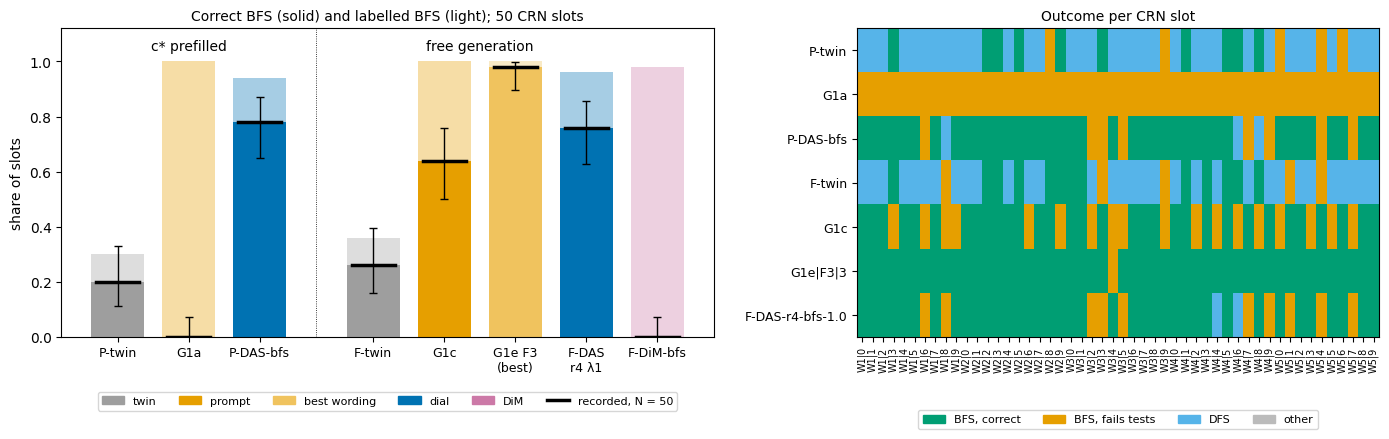

In [33]:
FIG_CELLS = [("P-twin", "twin", "prefilled"), ("G1a", "prompt", "prefilled"), ("P-DAS-bfs", "dial", "prefilled"),
             ("F-twin", "twin", "free"), ("G1c", "prompt", "free"), ("G1e|F3|3", "best wording", "free"),
             ("F-DAS-r4-bfs-1.0", "dial", "free"), ("F-DiM-bfs", "DiM", "free")]
COL = {"twin": "#9e9e9e", "prompt": "#e69f00", "best wording": "#f0c35e", "dial": "#0072b2", "DiM": "#cc79a7"}
summary = []
for c, kind, cond in FIG_CELLS:
    s = AN["cells"].get(c, {"n": 0})
    r = REC["analysis_cells"][c]
    summary.append({"cell": c, "arm": kind, "condition": cond, "n": s["n"], "correct BFS": s.get("correct_target"),
                    "labelled BFS": s.get("attempted_target"), "pass rate": s.get("pass_rate"),
                    "' queue' share": s.get("queue_share"),
                    "recorded correct/50": r["correct_target"], "recorded pass rate": r["pass_rate"]})
display(pd.DataFrame(summary).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
x = np.arange(len(FIG_CELLS)) + np.array([0, 0, 0, 0.6, 0.6, 0.6, 0.6, 0.6])
for i, (c, kind, cond) in enumerate(FIG_CELLS):
    s = AN["cells"].get(c, {"n": 0})
    if not s["n"]:
        continue
    n = s["n"]
    ax[0].bar(x[i], s["attempted_target"] / n, 0.75, color=COL[kind], alpha=0.35)
    ax[0].bar(x[i], s["correct_target"] / n, 0.75, color=COL[kind])
    lo, hi = s["correct_ci95"]
    ax[0].errorbar(x[i], s["correct_target"] / n, yerr=[[max(0.0, s["correct_target"] / n - lo)],
                                                         [max(0.0, hi - s["correct_target"] / n)]],
                   color="k", capsize=3, lw=1)
    ax[0].plot([x[i] - 0.3, x[i] + 0.3], [REC["analysis_cells"][c]["correct_target"] / 50] * 2, color="k", lw=2.5)
ax[0].set_xticks(x, [c.replace("F-DAS-r4-bfs-1.0", "F-DAS\nr4 λ1").replace("G1e|F3|3", "G1e F3\n(best)") for c, _, _ in FIG_CELLS],
                 fontsize=9)
ax[0].axvline(2.8, color="k", lw=0.6, ls=":")
ax[0].text(1, 1.04, "c* prefilled", ha="center", fontsize=10)
ax[0].text(5.1, 1.04, "free generation", ha="center", fontsize=10)
ax[0].set_ylim(0, 1.12)
ax[0].set_ylabel("share of slots")
ax[0].set_title(f"Correct BFS (solid) and labelled BFS (light); {len(S50_SEL)} CRN slots", fontsize=10)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=v, label=k) for k, v in COL.items()] +
             [plt.Line2D([], [], color="k", lw=2.5, label="recorded, N = 50")], fontsize=8, loc="upper center",
             bbox_to_anchor=(0.5, -0.16), ncol=6)

grid_cells = ["P-twin", "G1a", "P-DAS-bfs", "F-twin", "G1c", "G1e|F3|3", "F-DAS-r4-bfs-1.0"]
code_of = lambda r: 0 if r is None else (3 if (r["label"] == "bfs" and r["passed"]) else 2 if r["label"] == "bfs" else 1 if r["label"] == "dfs" else 4)  # noqa: E731
G = np.array([[code_of(EX[s]["cells"].get(c)) for s in S50_SEL] for c in grid_cells])
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["white", "#56b4e9", "#e69f00", "#009e73", "#bbbbbb"])
ax[1].imshow(G, cmap=cmap, vmin=-0.5, vmax=4.5, aspect="auto")
ax[1].set_yticks(range(len(grid_cells)), grid_cells, fontsize=9)
ax[1].set_xticks(range(len(S50_SEL)), [f"{w}|{k}" for w, k in S50_SEL], rotation=90, fontsize=7)
ax[1].set_title("Outcome per CRN slot", fontsize=10)
ax[1].legend(handles=[Patch(color=cmap(3), label="BFS, correct"), Patch(color=cmap(2), label="BFS, fails tests"),
                      Patch(color=cmap(1), label="DFS"), Patch(color=cmap(4), label="other")],
             fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
plt.tight_layout()
plt.show()

**Figure 3** is the activation geometry at block 17, position p_f, on real states.
- **(a)** The dial's plane: the first two DAS coordinates (seed 0). The 120 twin variants barely spread along it
  (dormant). The 40 forced-prompt sources separate by class, and the five twin states are moved to the BFS / DFS
  class means by the λ = 1 edit.
- **(b)** The twins' own manifold: the top two principal components of the 120 twin variants. The DAS edit's
  displacement (green arrows) is barely visible here, because most of it lies outside the directions along which
  the twins naturally vary.
- **(c)** The natural-variance share of $R_k$ against the Haar null, for the twins (V120) and with the forced sources
  added (V160).
- **(d)** The recorded layer sweep, replayed: p(` queue`) after a single-block full-state swap at p_f.

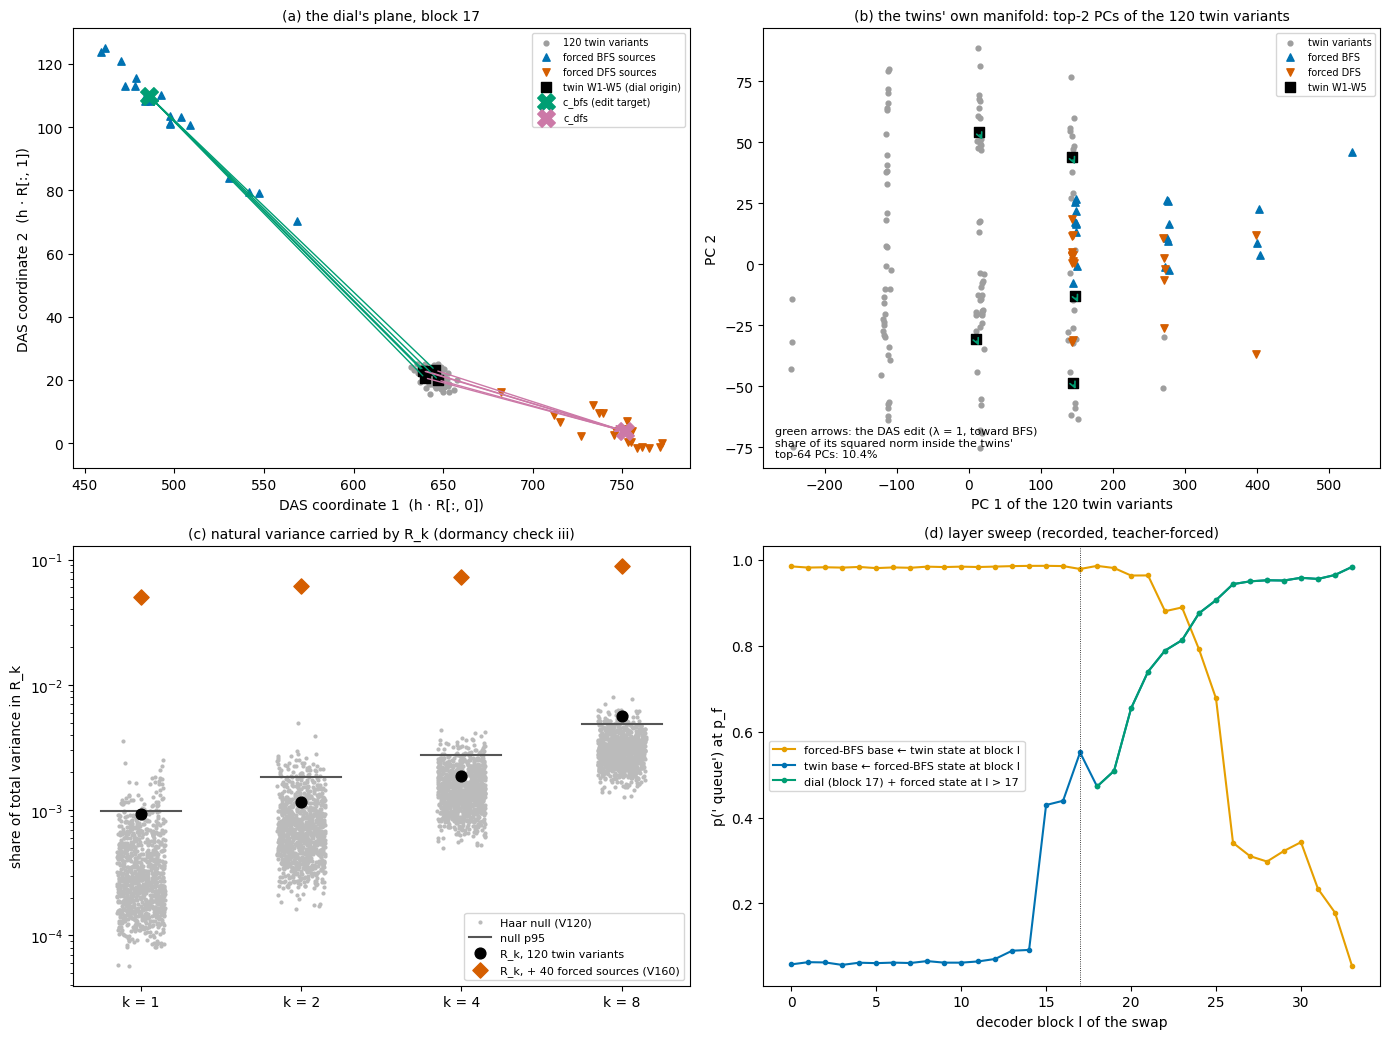

In [34]:
R0 = maps["R"][0]
P_tw = (Hv @ R0[:, :2]).cpu().numpy()
P_src = (Hs @ R0[:, :2]).cpu().numpy()
modes = np.array([m["mode"] for m in data["context"]["forced_source_states_L17"]["meta"]])
f_b, f_d = E["fn_for"]("DAS", 4, "bfs", 1.0), E["fn_for"]("DAS", 4, "dfs", 1.0)
TWb, TWd = f_b(TW_STATES), f_d(TW_STATES)
P0, Pb, Pd = [(T @ R0[:, :2]).cpu().numpy() for T in (TW_STATES, TWb, TWd)]
cb, cd = [E["target"](0, 4, Y)[:2].cpu().numpy() for Y in ("bfs", "dfs")]

fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
ax = axs.ravel()
ax[0].scatter(*P_tw.T, s=12, c="#9e9e9e", label="120 twin variants")
ax[0].scatter(*P_src[modes == "bfs"].T, s=28, marker="^", c="#0072b2", label="forced BFS sources")
ax[0].scatter(*P_src[modes == "dfs"].T, s=28, marker="v", c="#d55e00", label="forced DFS sources")
ax[0].scatter(*P0.T, s=50, marker="s", c="k", label="twin W1-W5 (dial origin)")
for i in range(5):
    ax[0].annotate("", Pb[i], P0[i], arrowprops=dict(arrowstyle="->", color="#009e73", lw=1))
    ax[0].annotate("", Pd[i], P0[i], arrowprops=dict(arrowstyle="->", color="#cc79a7", lw=1))
ax[0].scatter(*cb, s=160, marker="X", c="#009e73", label="c_bfs (edit target)")
ax[0].scatter(*cd, s=160, marker="X", c="#cc79a7", label="c_dfs")
ax[0].set_xlabel("DAS coordinate 1  (h · R[:, 0])")
ax[0].set_ylabel("DAS coordinate 2  (h · R[:, 1])")
ax[0].set_title("(a) the dial's plane, block 17", fontsize=10)
ax[0].legend(fontsize=7)

U = torch.from_numpy(pcs(Hv.cpu().numpy().astype(np.float64), C8.PC_MAIN)).float().to(DEV)      # [2560, 64]
mu = Hv.mean(0)
Q = lambda X: ((X - mu) @ U[:, :2]).cpu().numpy()      # noqa: E731
ax[1].scatter(*Q(Hv).T, s=12, c="#9e9e9e", label="twin variants")
ax[1].scatter(*Q(Hs)[modes == "bfs"].T, s=28, marker="^", c="#0072b2", label="forced BFS")
ax[1].scatter(*Q(Hs)[modes == "dfs"].T, s=28, marker="v", c="#d55e00", label="forced DFS")
q0, qb = Q(TW_STATES), Q(TWb)
ax[1].scatter(*q0.T, s=50, marker="s", c="k", label="twin W1-W5")
for i in range(5):
    ax[1].annotate("", qb[i], q0[i], arrowprops=dict(arrowstyle="->", color="#009e73", lw=1.2))
dh = TWb - TW_STATES
in64 = float(((dh @ U).norm(dim=1) ** 2 / dh.norm(dim=1) ** 2).mean())
ax[1].set_title("(b) the twins' own manifold: top-2 PCs of the 120 twin variants", fontsize=10)
ax[1].text(0.02, 0.02, f"green arrows: the DAS edit (λ = 1, toward BFS)\nshare of its squared norm inside the twins'\n"
           f"top-64 PCs: {in64:.1%}", transform=ax[1].transAxes, fontsize=8, va="bottom")
ax[1].set_xlabel("PC 1 of the 120 twin variants")
ax[1].set_ylabel("PC 2")
ax[1].legend(fontsize=7)

Hc = Hv - Hv.mean(0, keepdim=True)
Sig = (Hc.T @ Hc) / (Hv.shape[0] - 1)
trS = float(torch.trace(Sig))
for j, k in enumerate(C8.RANKS):
    a, b = nv120[str(k)], nv160[str(k)]
    # the null's spread: re-draw the Haar shares with natural_variance's generator (seed 9 + k)
    g = torch.Generator().manual_seed(9 + k)
    rs = []
    for _ in range(N_HAAR_VAR_DEMO):
        Rr = torch.linalg.qr(torch.randn(D_MODEL, k, generator=g).to(DEV))[0]
        rs.append(float(torch.trace(Rr.T @ Sig @ Rr)) / trS)
    ax[2].scatter(np.full(len(rs), j) + np.random.default_rng(k).uniform(-0.15, 0.15, len(rs)), rs, s=4, c="#bbbbbb",
                  label="Haar null (V120)" if j == 0 else None)
    ax[2].plot([j - 0.25, j + 0.25], [a["random_p95"]] * 2, c="#555555", lw=1.5, label="null p95" if j == 0 else None)
    ax[2].scatter(j, a["share"], s=60, c="k", zorder=3, label="R_k, 120 twin variants" if j == 0 else None)
    ax[2].scatter(j, b["share"], s=60, c="#d55e00", marker="D", zorder=3,
                  label="R_k, + 40 forced sources (V160)" if j == 0 else None)
ax[2].set_yscale("log")
ax[2].set_xticks(range(len(C8.RANKS)), [f"k = {k}" for k in C8.RANKS])
ax[2].set_ylabel("share of total variance in R_k")
ax[2].set_title("(c) natural variance carried by R_k (dormancy check iii)", fontsize=10)
ax[2].legend(fontsize=8, loc="lower right")

g_ = ls_rows.groupby("block")[["reverse_p_queue", "forward_p_queue", "dial_plus_forced_state_p_queue"]].mean()
ax[3].plot(g_.index, g_["reverse_p_queue"], "-o", ms=3, c="#e69f00", label="forced-BFS base ← twin state at block l")
ax[3].plot(g_.index, g_["forward_p_queue"], "-o", ms=3, c="#0072b2", label="twin base ← forced-BFS state at block l")
ax[3].plot(g_.index, g_["dial_plus_forced_state_p_queue"], "-o", ms=3, c="#009e73", label="dial (block 17) + forced state at l > 17")
ax[3].axvline(C8.L, c="k", lw=0.6, ls=":")
ax[3].set_xlabel("decoder block l of the swap")
ax[3].set_ylabel("p(' queue') at p_f")
ax[3].set_title("(d) layer sweep (recorded, teacher-forced)", fontsize=10)
ax[3].legend(fontsize=8, loc="center left")
plt.tight_layout()
plt.show()

### Summary

The cells above re-derived the following on CPU from the recorded artifacts:
- the checker gate;
- the hash-chained commitments;
- the edits of every free cell, applied to real block-17 states;
- iteration 7's natural-variance numbers (dormancy check iii) and its class targets;
- the committed decision positions and the free-dial predictions of COMMIT #2;
- the hidden-test pass flags of the headline programs;
- the committed statistics (P1–P7).

With `SLOTS_PER_TEMPLATE = 10` and `HT30_PER_TEMPLATE = 15`, the counts and p-values equal the recorded ones:
- `G1a` 0/50 vs `P-DAS-bfs` 39/50 (p = 3.6e-12);
- `F-twin` 13/50 vs `F-DAS-r4-bfs-1.0` 38/50 (p = 2.1e-7);
- `G1c` 32/50 vs the free dial (p = 0.21);
- interaction 0.66.

The model-dependent steps (sampling, the teacher-forced predictions, recovery and retention, the layer sweep) are
replayed from the recorded run. `RUN_GPU_STAGES` runs them for real.

**Runtime at this scale (the original one):** 88 s for the whole notebook, installs included, in a clean Python 3.12
venv on 2 CPU cores. The largest parts are the hidden tests on 460 programs (≈ 37 s, several programs time out by
design) and the 1,000-subspace Haar null (≈ 15 s). The cell below prints the time spent since the imports.

In [35]:
print("elapsed in this kernel since the imports cell:", f"{time.time() - _T_START:.0f}s" if "_T_START" in globals() else "n/a")
print("config:", dict(SLOTS_PER_TEMPLATE=SLOTS_PER_TEMPLATE, HT30_PER_TEMPLATE=HT30_PER_TEMPLATE,
                      RESCORE_CELLS=RESCORE_CELLS, N_HAAR_VAR_DEMO=N_HAAR_VAR_DEMO))

elapsed in this kernel since the imports cell: 63s
config: {'SLOTS_PER_TEMPLATE': 10, 'HT30_PER_TEMPLATE': 15, 'RESCORE_CELLS': ['P-twin', 'G1a', 'P-DAS-bfs', 'F-twin', 'G1c', 'F-DAS-r4-bfs-1.0', 'F-DiM-bfs', 'G1e|F3|3'], 'N_HAAR_VAR_DEMO': 1000}
